In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

current_dir = Path.cwd().resolve()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

data_root = (
    project_root.parent
    / "Ship_of_theseus_paraphrased_copus"
    / "paraphrased_datasets"
)

assert (project_root / "pyproject.toml").exists(), "Project root not found."
assert data_root.is_dir(), f"Data directory not found: {data_root}"

csv_files = sorted(data_root.glob("*_paraphrased.csv"))

print(f"Python: {sys.executable}")
print(f"Project root: {project_root}")
print(f"Data directory: {data_root}")
print(f"CSV files found: {len(csv_files)}")

Python: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/.venv/bin/python
Project root: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus
Data directory: /Users/ikemefunayang/Documents/cs6120-group-project/Ship_of_theseus_paraphrased_copus/paraphrased_datasets
CSV files found: 7


In [2]:
datasets = {}
audit_rows = []

for path in csv_files:
    domain = path.stem.removesuffix("_paraphrased")

    df = pd.read_csv(
        path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    required_columns = {"source", "key", "text", "version_name"}
    assert required_columns.issubset(df.columns), (
        f"Missing columns in {path.name}"
    )

    datasets[domain] = df

    empty_text = df["text"].str.strip().eq("")
    original_mask = df["version_name"].eq("original")

    audit_rows.append({
        "domain": domain,
        "rows": len(df),
        "original_rows": original_mask.sum(),
        "sources": df["source"].nunique(),
        "versions": df["version_name"].nunique(),
        "empty_texts": empty_text.sum(),
        "duplicate_rows": df.duplicated(
            subset=["source", "key", "version_name"]
        ).sum(),
    })

audit_table = pd.DataFrame(audit_rows).set_index("domain")

display(audit_table)
print(f"Total rows: {audit_table['rows'].sum():,}")
print(f"Total original rows: {audit_table['original_rows'].sum():,}")

,rows,original_rows,sources,versions,empty_texts,duplicate_rows
domain,,,,,,
cmv,35405,1626,7,22,1,0
eli5,69270,3160,7,22,1,0
sci_gen,60166,2797,7,22,1,0
tldr,53519,2444,7,22,2,0
wp,58417,2768,7,22,2,0
xsum,70388,3227,7,22,2,0
yelp,72847,3320,7,22,1,0


Total rows: 420,012
Total original rows: 19,342


In [3]:
configuration_map = {
    "chatgpt": ("ChatGPT", "default"),
    "palm": ("PaLM", "default"),
    "pegasus(full)": ("Pegasus", "full"),
    "pegasus(slight)": ("Pegasus", "slight"),
    "dipper": ("DIPPER", "default"),
    "dipper(low)": ("DIPPER", "low"),
    "dipper(high)": ("DIPPER", "high"),
}

configuration_versions = {
    configuration: [
        "_".join([configuration] * iteration)
        for iteration in range(1, 4)
    ]
    for configuration in configuration_map
}

selected_versions = ["original"] + [
    version
    for versions in configuration_versions.values()
    for version in versions
]

aligned_datasets = {}
coverage_rows = []

for domain, df in datasets.items():
    valid = df.loc[
        df["version_name"].isin(selected_versions)
        & df["text"].str.strip().ne("")
    ].copy()

    assert not valid.duplicated(
        subset=["source", "key", "version_name"]
    ).any(), f"Duplicate identities in {domain}"

    wide = valid.pivot(
        index=["source", "key"],
        columns="version_name",
        values="text",
    ).reindex(columns=selected_versions)

    original_count = int(wide["original"].notna().sum())
    coverage = {
        "domain": domain,
        "originals": original_count,
    }

    for configuration, versions in configuration_versions.items():
        coverage[configuration] = int(
            wide[["original"] + versions].notna().all(axis=1).sum()
        )

    shared = wide.dropna(subset=selected_versions).copy()
    aligned_datasets[domain] = shared

    coverage["shared_complete"] = len(shared)
    coverage["retained_pct"] = round(
        100 * len(shared) / original_count, 2
    )
    coverage_rows.append(coverage)

coverage_table = pd.DataFrame(coverage_rows).set_index("domain")

configuration_table = pd.DataFrame([
    {
        "configuration": configuration,
        "paraphraser": paraphraser,
        "setting": setting,
    }
    for configuration, (paraphraser, setting)
    in configuration_map.items()
])

display(configuration_table)
display(coverage_table)

print(f"Configurations: {len(configuration_map)}")
print(f"Selected version labels: {len(selected_versions)}")
print(
    "Total originals complete across all configurations: "
    f"{coverage_table['shared_complete'].sum():,}"
)

,configuration,paraphraser,setting
0,chatgpt,ChatGPT,default
1,palm,PaLM,default
2,pegasus(full),Pegasus,full
3,pegasus(slight),Pegasus,slight
4,dipper,DIPPER,default
5,dipper(low),DIPPER,low
6,dipper(high),DIPPER,high


,originals,chatgpt,palm,pegasus(full),pegasus(slight),dipper,dipper(low),dipper(high),shared_complete,retained_pct
domain,,,,,,,,,,
cmv,1626,1603,1514,1625,1626,1626,1626,1625,1489,91.57
eli5,3160,3128,3095,3160,3160,3160,3160,3159,3065,96.99
sci_gen,2797,2738,1663,2796,2797,2797,2797,2796,1634,58.42
tldr,2444,2416,2359,2444,2444,2444,2444,2442,2331,95.38
wp,2768,2701,1968,2763,2768,2768,2768,2766,1921,69.40
xsum,3227,3184,3053,3220,3227,3227,3227,3225,3003,93.06
yelp,3320,3279,3272,3320,3320,3320,3320,3319,3231,97.32


Configurations: 7
Selected version labels: 22
Total originals complete across all configurations: 16,674


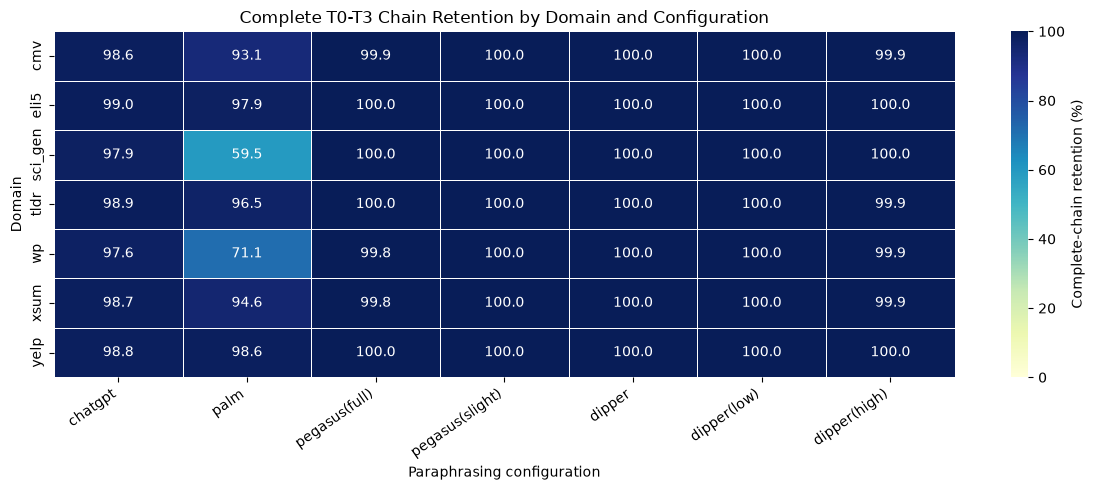

In [4]:
configuration_names = list(configuration_map)

retention_table = (
    coverage_table[configuration_names]
    .div(coverage_table["originals"], axis=0)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(12, 5))

sns.heatmap(
    retention_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Complete-chain retention (%)"},
    ax=ax,
)

ax.set_title("Complete T0-T3 Chain Retention by Domain and Configuration")
ax.set_xlabel("Paraphrasing configuration")
ax.set_ylabel("Domain")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")

fig.tight_layout()

figures_dir = project_root / "figures"
metadata_dir = project_root / "data" / "metadata"

figures_dir.mkdir(parents=True, exist_ok=True)
metadata_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "01_chain_retention.png",
    dpi=300,
    bbox_inches="tight",
)

audit_table.to_csv(metadata_dir / "data_audit.csv")
coverage_table.to_csv(metadata_dir / "chain_coverage.csv")
configuration_table.to_csv(
    metadata_dir / "paraphraser_configurations.csv",
    index=False,
)

plt.show()

,count,mean,median,p90,maximum
domain,,,,,
cmv,1626,374.8,295.0,798.0,1299
eli5,3160,273.9,160.0,739.0,5634
sci_gen,2797,292.6,181.0,798.4,973
tldr,2444,191.2,113.0,466.7,948
wp,2768,414.8,330.5,806.0,1922
xsum,3227,232.5,162.0,518.0,2360
yelp,3320,217.6,121.0,655.2,930


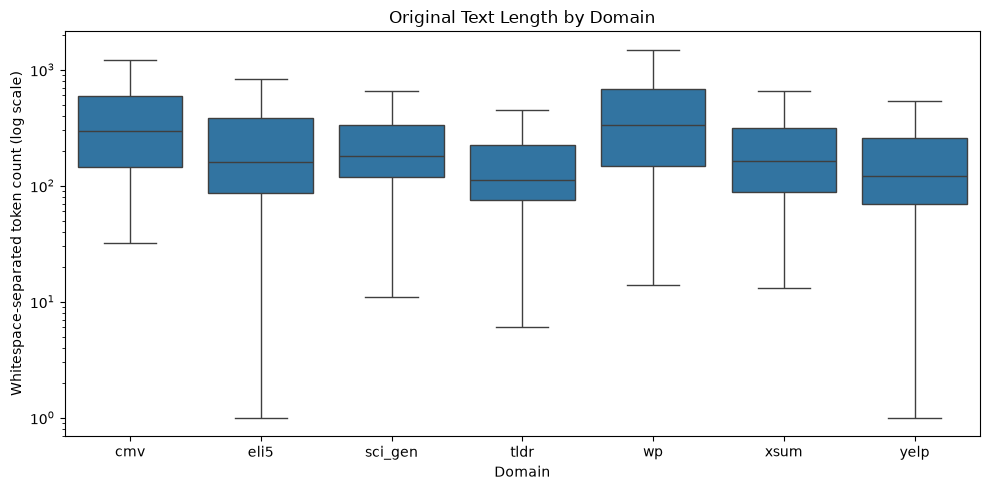

In [5]:
original_frames = []

for domain, df in datasets.items():
    originals = df.loc[
        df["version_name"].eq("original")
        & df["text"].str.strip().ne(""),
        ["source", "key", "text"],
    ].copy()

    originals["domain"] = domain

    # Count whitespace-separated tokens as a basic length measure.
    originals["word_count"] = originals["text"].str.split().str.len()

    original_frames.append(originals)

original_lengths = pd.concat(original_frames, ignore_index=True)

length_summary = (
    original_lengths.groupby("domain")["word_count"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        p90=lambda values: values.quantile(0.90),
        maximum="max",
    )
    .round(1)
)

display(length_summary)

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=original_lengths,
    x="domain",
    y="word_count",
    order=sorted(datasets),
    showfliers=False,
    ax=ax,
)

ax.set_yscale("log")
ax.set_title("Original Text Length by Domain")
ax.set_xlabel("Domain")
ax.set_ylabel("Whitespace-separated token count (log scale)")

fig.tight_layout()
fig.savefig(
    figures_dir / "02_original_text_length.png",
    dpi=300,
    bbox_inches="tight",
)

length_summary.to_csv(metadata_dir / "original_length_summary.csv")

plt.show()

In [6]:
short_originals = original_lengths.loc[
    original_lengths["word_count"] <= 5,
    ["domain", "source", "key", "word_count", "text"],
].sort_values(["domain", "word_count"])

print(f"Original texts with at most 5 tokens: {len(short_originals)}")

with pd.option_context("display.max_colwidth", 200):
    display(short_originals)

Original texts with at most 5 tokens: 21


,domain,source,key,word_count,text
2536,eli5,PaLM,eli5-612,1,counted.
4407,eli5,PaLM,eli5-19891,1,""""
3441,eli5,PaLM,eli5-747,3,meet and berate
4275,eli5,PaLM,eli5-19871,4,not have nutrition requirements.
1674,eli5,PaLM,eli5-484,5,a fascinating topic of study.
1934,eli5,PaLM,eli5-521,5,That's how it is here.
2152,eli5,PaLM,eli5-555,5,is lay on a pillow.
4683,eli5,PaLM,eli5-19933,5,"weaken, the spine curves inward."
17504,yelp,PaLM,yelp-713,1,burgers.
18175,yelp,PaLM,yelp-31850,1,tea


In [7]:
invalid_records = []

for domain, df in datasets.items():
    has_content = df["text"].map(
        lambda text: any(character.isalnum() for character in text)
    )

    invalid = df.loc[
        ~has_content,
        ["source", "key", "version_name", "text"],
    ].copy()

    invalid.insert(0, "domain", domain)
    invalid_records.append(invalid)

invalid_text_table = pd.concat(invalid_records, ignore_index=True)

display(invalid_text_table)

clean_aligned_datasets = {}
cleaning_rows = []

for domain, wide in aligned_datasets.items():
    valid_cells = wide.apply(
        lambda column: column.map(
            lambda text: any(character.isalnum() for character in text)
        )
    )

    clean = wide.loc[valid_cells.all(axis=1)].copy()
    clean_aligned_datasets[domain] = clean

    cleaning_rows.append({
        "domain": domain,
        "before": len(wide),
        "excluded": len(wide) - len(clean),
        "after": len(clean),
        "short_originals_retained": int(
            clean["original"].str.split().str.len().le(5).sum()
        ),
    })

cleaning_table = pd.DataFrame(cleaning_rows).set_index("domain")

display(cleaning_table)

invalid_text_table.to_csv(
    metadata_dir / "invalid_text_records.csv",
    index=False,
)
cleaning_table.to_csv(metadata_dir / "content_cleaning_summary.csv")

print(
    "Total clean shared originals: "
    f"{cleaning_table['after'].sum():,}"
)

,domain,source,key,version_name,text
0,cmv,OpenAI,cmv-367,dipper(high)_dipper(high),
1,eli5,PaLM,eli5-19891,original,""""
2,eli5,PaLM,eli5-19891,pegasus(slight),""""
3,eli5,PaLM,eli5-19891,pegasus(full),""""
4,eli5,PaLM,eli5-19891,pegasus(full)_pegasus(full),""""
5,eli5,PaLM,eli5-19891,pegasus(full)_pegasus(full)_pegasus(full),""""
6,eli5,PaLM,eli5-19891,pegasus(slight)_pegasus(slight),""""
7,eli5,PaLM,eli5-19891,pegasus(slight)_pegasus(slight)_pegasus(slight),""""
8,eli5,Tsinghua,eli5-16794,palm_palm,** ** ** ** ** ** ** ** ** ** ** ** ** ** ** *...
9,eli5,Tsinghua,eli5-16794,palm_palm_palm,** ** ** ** ** ** ** ** ** ** ** ** ** ** ** *...


,before,excluded,after,short_originals_retained
domain,,,,
cmv,1489,0,1489,0
eli5,3065,4,3061,7
sci_gen,1634,3,1631,0
tldr,2331,1,2330,0
wp,1921,2,1919,0
xsum,3003,3,3000,0
yelp,3231,2,3229,13


Total clean shared originals: 16,659


,configuration,iteration,pairs,median_ratio,p25,p75
0,chatgpt,1,16659,0.927,0.783,1.034
1,chatgpt,2,16659,0.908,0.744,1.028
2,chatgpt,3,16659,0.900,0.730,1.026
3,dipper,1,16659,0.896,0.803,0.992
4,dipper,2,16659,0.816,0.703,0.937
5,dipper,3,16659,0.754,0.628,0.887
6,dipper(high),1,16659,0.734,0.520,0.992
7,dipper(high),2,16659,0.478,0.304,0.710
8,dipper(high),3,16659,0.323,0.191,0.514
9,dipper(low),1,16659,0.944,0.877,1.000


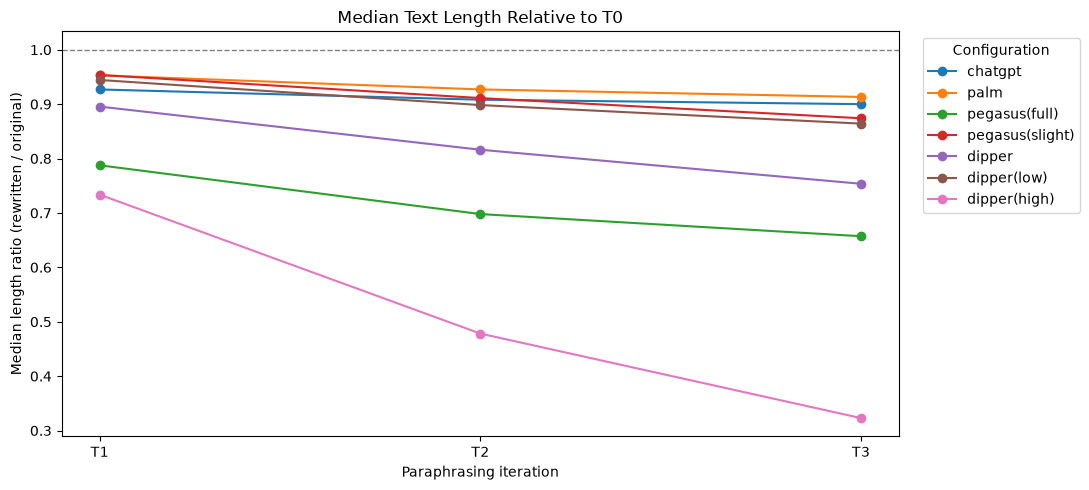

In [8]:
length_change_frames = []

for domain, wide in clean_aligned_datasets.items():
    original_counts = wide["original"].str.split().str.len()

    for configuration, versions in configuration_versions.items():
        paraphraser, setting = configuration_map[configuration]

        for iteration, version in enumerate(versions, start=1):
            rewritten_counts = wide[version].str.split().str.len()

            frame = wide.reset_index()[["source", "key"]].copy()
            frame["domain"] = domain
            frame["configuration"] = configuration
            frame["paraphraser"] = paraphraser
            frame["setting"] = setting
            frame["iteration"] = iteration
            frame["original_length"] = original_counts.to_numpy()
            frame["rewritten_length"] = rewritten_counts.to_numpy()
            frame["length_ratio"] = (
                rewritten_counts / original_counts
            ).to_numpy()

            length_change_frames.append(frame)

length_changes = pd.concat(length_change_frames, ignore_index=True)

length_change_summary = (
    length_changes.groupby(["configuration", "iteration"])
    .agg(
        pairs=("length_ratio", "size"),
        median_ratio=("length_ratio", "median"),
        p25=("length_ratio", lambda values: values.quantile(0.25)),
        p75=("length_ratio", lambda values: values.quantile(0.75)),
    )
    .reset_index()
)

display(length_change_summary.round(3))

fig, ax = plt.subplots(figsize=(11, 5))

for configuration in configuration_map:
    subset = length_change_summary.loc[
        length_change_summary["configuration"].eq(configuration)
    ]

    ax.plot(
        subset["iteration"],
        subset["median_ratio"],
        marker="o",
        label=configuration,
    )

ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])
ax.set_title("Median Text Length Relative to T0")
ax.set_xlabel("Paraphrasing iteration")
ax.set_ylabel("Median length ratio (rewritten / original)")
ax.legend(title="Configuration", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.tight_layout()
fig.savefig(
    figures_dir / "03_length_change.png",
    dpi=300,
    bbox_inches="tight",
)

length_change_summary.to_csv(
    metadata_dir / "length_change_summary.csv",
    index=False,
)

plt.show()

In [9]:
manifest_frames = []

for domain, wide in clean_aligned_datasets.items():
    manifest = wide.reset_index()[["source", "key"]].copy()
    manifest.insert(0, "domain", domain)
    manifest_frames.append(manifest)

sample_manifest = pd.concat(manifest_frames, ignore_index=True)

assert not sample_manifest.duplicated(
    subset=["domain", "source", "key"]
).any()

sample_manifest.to_csv(
    metadata_dir / "shared_sample_manifest.csv",
    index=False,
)

display(
    sample_manifest.groupby(["domain", "source"])
    .size()
    .unstack(fill_value=0)
)

print(f"Saved sample identities: {len(sample_manifest):,}")

source,BigScience,Eleuther-AI,Human,LLAMA,OpenAI,PaLM,Tsinghua
domain,,,,,,,
cmv,224,181,227,237,233,159,228
eli5,439,358,452,444,457,460,451
sci_gen,177,97,227,233,464,231,202
tldr,344,291,371,349,373,246,356
wp,318,220,255,311,415,89,311
xsum,460,407,336,459,452,433,453
yelp,448,444,483,475,447,468,464


Saved sample identities: 16,659


In [11]:
import sacrebleu
from rouge_score import rouge_scorer
from tqdm import tqdm

print(f"SacreBLEU version: {sacrebleu.__version__}")
print("Baseline dependencies ready")

SacreBLEU version: 2.6.0
Baseline dependencies ready


In [12]:
from time import perf_counter
from sacrebleu.metrics import BLEU

bleu_metric = BLEU(
    tokenize="13a",
    lowercase=False,
    effective_order=True,
)

rouge_metric = rouge_scorer.RougeScorer(
    ["rouge1", "rougeL"],
    use_stemmer=True,
)

pilot_samples = {
    domain: wide.sample(n=20, random_state=6120)
    for domain, wide in clean_aligned_datasets.items()
}

total_pairs = sum(
    len(sample) for sample in pilot_samples.values()
) * 21

pilot_rows = []
start = perf_counter()

with tqdm(total=total_pairs, desc="Pilot baseline") as progress:
    for domain, sample in pilot_samples.items():
        for configuration, versions in configuration_versions.items():
            for iteration, version in enumerate(versions, start=1):
                for (source, key), row in sample.iterrows():
                    reference = row["original"]
                    candidate = row[version]
                    rouge = rouge_metric.score(reference, candidate)

                    pilot_rows.append({
                        "domain": domain,
                        "source": source,
                        "key": key,
                        "configuration": configuration,
                        "iteration": iteration,
                        "BLEU": bleu_metric.sentence_score(
                            candidate, [reference]
                        ).score,
                        "ROUGE-1_F1": rouge["rouge1"].fmeasure,
                        "ROUGE-L_F1": rouge["rougeL"].fmeasure,
                    })

                    progress.update(1)

pilot_scores = pd.DataFrame(pilot_rows)
elapsed = perf_counter() - start

pilot_summary = (
    pilot_scores.groupby(["configuration", "iteration"])
    .agg(
        pairs=("BLEU", "size"),
        mean_sentence_BLEU=("BLEU", "mean"),
        mean_ROUGE1_F1=("ROUGE-1_F1", "mean"),
        mean_ROUGEL_F1=("ROUGE-L_F1", "mean"),
    )
)

display(pilot_summary.round(4))
print(f"Original texts: {sum(map(len, pilot_samples.values())):,}")
print(f"Text pairs: {len(pilot_scores):,}")
print(f"Elapsed time: {elapsed:.2f} seconds")

Pilot baseline: 100%|█████████████████████| 2940/2940 [00:23<00:00, 126.61it/s]


pairs  mean_sentence_BLEU  mean_ROUGE1_F1  \
configuration   iteration                                              
chatgpt         1            140             25.1940          0.6272   
                2            140             21.5217          0.5919   
                3            140             18.7780          0.5668   
dipper          1            140             19.1381          0.5939   
                2            140             10.8747          0.5086   
                3            140              7.7097          0.4614   
dipper(high)    1            140              1.5591          0.2347   
                2            140              0.8575          0.1958   
                3            140              0.5233          0.1497   
dipper(low)     1            140             53.9670          0.8246   
                2            140             40.7305          0.7532   
                3            140             34.4746          0.7130   
palm            1            140             44.8791          0.7200   
                2            140             37.2544          0.6643   
                3            140             34.1124          0.6396   
pegasus(full)   1            140             43.7014          0.7784   
                2            140             31.1342          0.6873   
                3            140             26.5508          0.6526   
pegasus(slight) 1            140             83.7082          0.9360   
                2            140             73.0305          0.8931   
                3            140             64.6802          0.8568   

                           mean_ROUGEL_F1  
configuration   iteration                  
chatgpt         1                  0.5241  
                2                  0.4701  
                3                  0.4396  
dipper          1                  0.3683  
                2                  0.2995  
                3                  0.2550  
dipper(high)    1                  0.1228  
                2                  0.1068  
                3                  0.0888  
dipper(low)     1                  0.7189  
                2                  0.6240  
                3                  0.5662  
palm            1                  0.6573  
                2                  0.5912  
                3                  0.5603  
pegasus(full)   1                  0.6749  
                2                  0.5830  
                3                  0.5345  
pegasus(slight) 1                  0.9134  
                2                  0.8495  
                3                  0.8016

Original texts: 140
Text pairs: 2,940
Elapsed time: 23.24 seconds


In [13]:
results_dir = project_root / "experiments" / "lexical_baseline_v1"
results_dir.mkdir(parents=True, exist_ok=True)

baseline_summary_rows = []

for domain, wide in clean_aligned_datasets.items():
    scores_path = results_dir / f"{domain}_pair_scores.csv"

    if scores_path.exists():
        domain_scores = pd.read_csv(
            scores_path,
            dtype={"source": str, "key": str},
        )
        print(f"Loaded saved scores: {domain}")
    else:
        domain_rows = []
        total_pairs = len(wide) * 21

        with tqdm(total=total_pairs, desc=domain) as progress:
            for configuration, versions in configuration_versions.items():
                for iteration, version in enumerate(versions, start=1):
                    for (source, key), row in wide.iterrows():
                        reference = row["original"]
                        candidate = row[version]
                        rouge = rouge_metric.score(reference, candidate)

                        domain_rows.append({
                            "domain": domain,
                            "source": source,
                            "key": key,
                            "configuration": configuration,
                            "iteration": iteration,
                            "sentence_BLEU": bleu_metric.sentence_score(
                                candidate, [reference]
                            ).score,
                            "ROUGE-1_F1": rouge["rouge1"].fmeasure,
                            "ROUGE-L_F1": rouge["rougeL"].fmeasure,
                        })

                        progress.update(1)

        domain_scores = pd.DataFrame(domain_rows)
        domain_scores.to_csv(scores_path, index=False)
        print(f"Saved scores: {domain}")

    assert len(domain_scores) == len(wide) * 21

    for configuration, versions in configuration_versions.items():
        for iteration, version in enumerate(versions, start=1):
            subset = domain_scores.loc[
                domain_scores["configuration"].eq(configuration)
                & domain_scores["iteration"].eq(iteration)
            ]

            corpus_bleu = bleu_metric.corpus_score(
                wide[version].tolist(),
                [wide["original"].tolist()],
            ).score

            baseline_summary_rows.append({
                "domain": domain,
                "configuration": configuration,
                "iteration": iteration,
                "pairs": len(subset),
                "corpus_BLEU": corpus_bleu,
                "mean_sentence_BLEU": subset["sentence_BLEU"].mean(),
                "mean_ROUGE1_F1": subset["ROUGE-1_F1"].mean(),
                "mean_ROUGEL_F1": subset["ROUGE-L_F1"].mean(),
            })

    pd.DataFrame(baseline_summary_rows).to_csv(
        results_dir / "baseline_by_domain.csv",
        index=False,
    )

baseline_by_domain = pd.DataFrame(baseline_summary_rows)

display(baseline_by_domain.round(4))
print("Full lexical baseline complete")
print(f"BLEU signature: {bleu_metric.get_signature()}")

cmv: 100%|███████████████████████████████| 31269/31269 [07:05<00:00, 73.44it/s]


Saved scores: cmv


eli5: 100%|█████████████████████████████| 64281/64281 [09:44<00:00, 109.99it/s]


Saved scores: eli5


sci_gen: 100%|██████████████████████████| 34251/34251 [04:45<00:00, 119.93it/s]


...

Saved scores: xsum


yelp: 100%|█████████████████████████████| 67809/67809 [07:53<00:00, 143.10it/s]


Saved scores: yelp


,domain,configuration,iteration,pairs,corpus_BLEU,mean_sentence_BLEU,mean_ROUGE1_F1,mean_ROUGEL_F1
0,cmv,chatgpt,1,1489,20.7843,20.9675,0.5893,0.4790
1,cmv,chatgpt,2,1489,17.3721,18.4391,0.5599,0.4351
2,cmv,chatgpt,3,1489,15.2803,15.4749,0.5302,0.4010
3,cmv,palm,1,1489,29.8099,33.2802,0.6283,0.5521
4,cmv,palm,2,1489,22.1462,26.3850,0.5692,0.4813
...,...,...,...,...,...,...,...,...
142,yelp,dipper(low),2,3229,45.5960,41.2226,0.7640,0.6341
143,yelp,dipper(low),3,3229,38.2255,34.4990,0.7210,0.5710
144,yelp,dipper(high),1,3229,3.5513,1.6949,0.2427,0.1266
145,yelp,dipper(high),2,3229,1.3591,0.9768,0.2010,0.1077


Full lexical baseline complete
BLEU signature: nrefs:1|case:mixed|eff:yes|tok:13a|smooth:exp|version:2.6.0


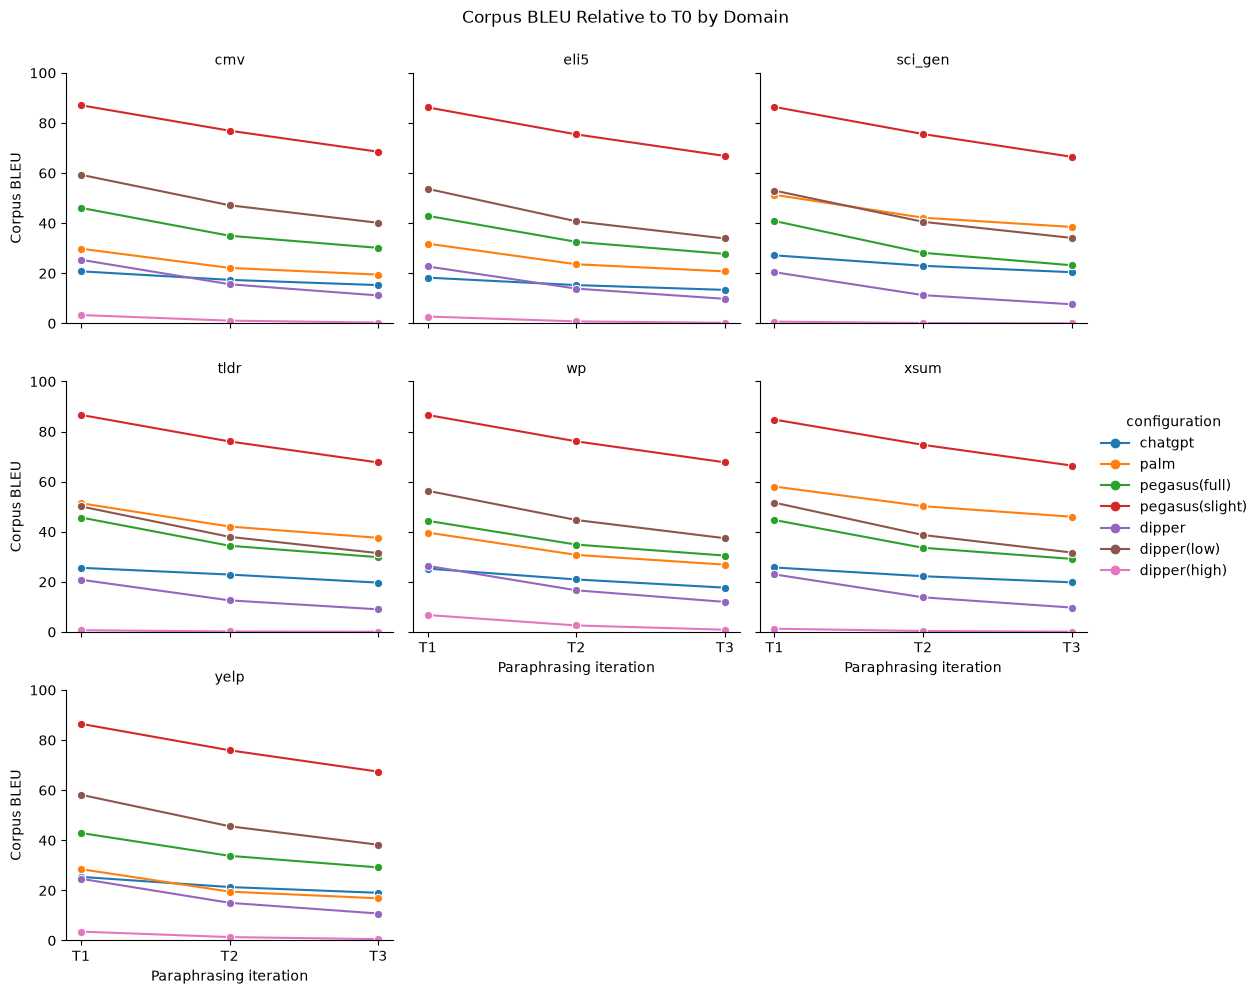

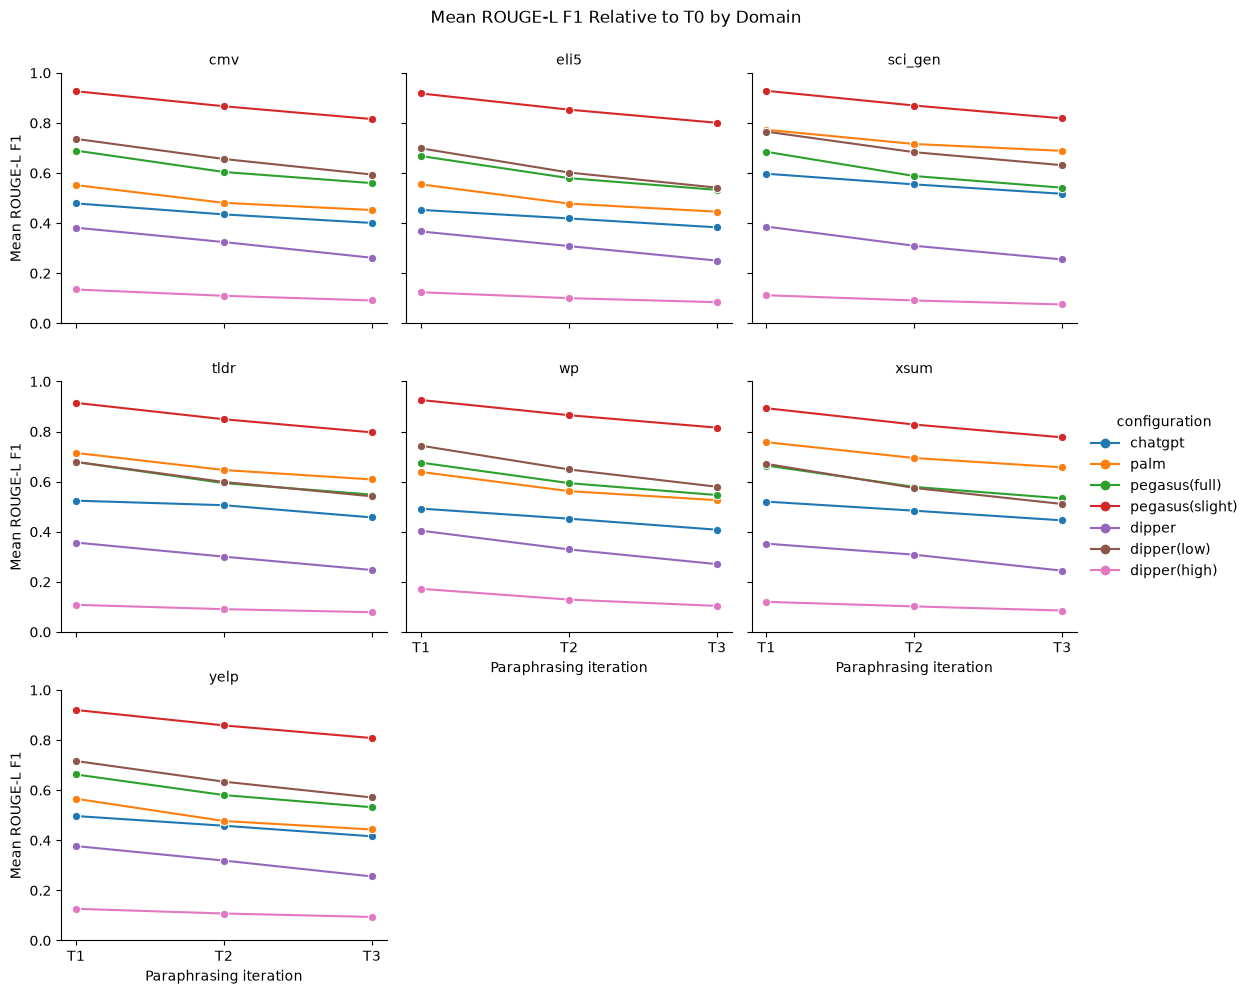

In [14]:
plot_metrics = {
    "corpus_BLEU": ("Corpus BLEU", "04_bleu_by_domain.png"),
    "mean_ROUGEL_F1": ("Mean ROUGE-L F1", "05_rougel_by_domain.png"),
}

for metric, (label, filename) in plot_metrics.items():
    grid = sns.relplot(
        data=baseline_by_domain,
        x="iteration",
        y=metric,
        hue="configuration",
        hue_order=list(configuration_map),
        col="domain",
        col_order=sorted(clean_aligned_datasets),
        col_wrap=3,
        kind="line",
        marker="o",
        estimator=None,
        palette="tab10",
        height=3.2,
        aspect=1.15,
        facet_kws={"sharex": True, "sharey": True},
    )

    grid.set_titles("{col_name}")
    grid.set_axis_labels("Paraphrasing iteration", label)

    for ax in grid.axes.flat:
        ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])

        if metric == "corpus_BLEU":
            ax.set_ylim(0, 100)
        else:
            ax.set_ylim(0, 1)

    grid.figure.suptitle(
        f"{label} Relative to T0 by Domain",
        y=1.03,
    )

    grid.figure.savefig(
        figures_dir / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [15]:
overall_rows = []

for configuration, versions in tqdm(
    configuration_versions.items(),
    total=len(configuration_versions),
    desc="Overall summary",
):
    paraphraser, setting = configuration_map[configuration]

    for iteration, version in enumerate(versions, start=1):
        references = []
        candidates = []

        for wide in clean_aligned_datasets.values():
            references.extend(wide["original"].tolist())
            candidates.extend(wide[version].tolist())

        subset = baseline_by_domain.loc[
            baseline_by_domain["configuration"].eq(configuration)
            & baseline_by_domain["iteration"].eq(iteration)
        ]

        pair_count = int(subset["pairs"].sum())

        assert len(subset) == len(clean_aligned_datasets)
        assert pair_count == len(references) == len(candidates)

        overall_rows.append({
            "paraphraser": paraphraser,
            "setting": setting,
            "configuration": configuration,
            "iteration": iteration,
            "pairs": pair_count,
            "corpus_BLEU": bleu_metric.corpus_score(
                candidates,
                [references],
            ).score,
            "mean_ROUGE1_F1": (
                subset["mean_ROUGE1_F1"] * subset["pairs"]
            ).sum() / pair_count,
            "mean_ROUGEL_F1": (
                subset["mean_ROUGEL_F1"] * subset["pairs"]
            ).sum() / pair_count,
        })

baseline_overall = pd.DataFrame(overall_rows)

assert len(baseline_overall) == 21
assert baseline_overall["pairs"].eq(16659).all()

baseline_overall.to_csv(
    results_dir / "baseline_overall.csv",
    index=False,
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(baseline_overall.round(4))

print(f"Summary rows: {len(baseline_overall)}")
print(f"Originals per comparison: {baseline_overall['pairs'].iloc[0]:,}")
print(f"Total evaluated pairs: {baseline_overall['pairs'].sum():,}")

Overall summary: 100%|███████████████████████████| 7/7 [02:49<00:00, 24.18s/it]


,paraphraser,setting,configuration,iteration,pairs,corpus_BLEU,mean_ROUGE1_F1,mean_ROUGEL_F1
0,ChatGPT,default,chatgpt,1,16659,23.8357,0.6129,0.5045
1,ChatGPT,default,chatgpt,2,16659,20.2103,0.5905,0.4690
2,ChatGPT,default,chatgpt,3,16659,17.7006,0.5563,0.4287
3,PaLM,default,palm,1,16659,40.3247,0.7086,0.6466
4,PaLM,default,palm,2,16659,31.7135,0.6497,0.5736
5,PaLM,default,palm,3,16659,28.2675,0.6230,0.5398
6,Pegasus,full,pegasus(full),1,16659,43.9678,0.7808,0.6723
7,Pegasus,full,pegasus(full),2,16659,33.4570,0.6957,0.5864
8,Pegasus,full,pegasus(full),3,16659,28.8491,0.6567,0.5398
9,Pegasus,slight,pegasus(slight),1,16659,86.2939,0.9410,0.9161


Summary rows: 21
Originals per comparison: 16,659
Total evaluated pairs: 349,839


In [16]:
import torch
import bert_score
import sys

print(f"Python version: {sys.version.split()[0]}")
print(f"PyTorch version: {torch.__version__}")
print(f"BERTScore version: {bert_score.__version__}")
print(f"MPS available: {torch.backends.mps.is_available()}")

Python version: 3.13.1
PyTorch version: 2.14.1
BERTScore version: 0.3.12
MPS available: True


In [17]:
from bert_score import BERTScorer
from time import perf_counter

start = perf_counter()

bert_scorer = BERTScorer(
    model_type="roberta-large",
    num_layers=17,
    lang="en",
    device="mps",
    batch_size=2,
    idf=False,
    rescale_with_baseline=False,
)

print(f"Model loaded in {perf_counter() - start:.2f} seconds")
print(f"BERTScore configuration: {bert_scorer.hash}")

Loading weights: 100%|████████████████████| 389/389 [00:00<00:00, 10278.54it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded in 21.74 seconds
BERTScore configuration: roberta-large_L17_no-idf_version=0.3.12(hug_trans=5.19.0)


In [18]:
tokenizer = bert_scorer._tokenizer
token_limit = tokenizer.model_max_length

token_length_rows = []

for domain, wide in tqdm(
    clean_aligned_datasets.items(),
    total=len(clean_aligned_datasets),
    desc="Checking original token lengths",
):
    texts = wide["original"].tolist()
    lengths = []

    for start in range(0, len(texts), 128):
        encoded = tokenizer(
            texts[start:start + 128],
            add_special_tokens=True,
            truncation=False,
            padding=False,
            return_length=True,
            verbose=False,
        )
        lengths.extend(encoded["length"])

    counts = pd.Series(lengths)

    token_length_rows.append({
        "domain": domain,
        "originals": len(counts),
        "median_tokens": counts.median(),
        "max_tokens": counts.max(),
        "over_limit": int(counts.gt(token_limit).sum()),
        "over_limit_pct": 100 * counts.gt(token_limit).mean(),
    })

token_length_summary = pd.DataFrame(
    token_length_rows
).set_index("domain")

display(token_length_summary.round(2))
print(f"Model token limit including special tokens: {token_limit}")

token_length_summary.to_csv(
    metadata_dir / "bertscore_original_token_lengths.csv"
)

Checking original token lengths: 100%|███████████| 7/7 [00:01<00:00,  4.85it/s]


,originals,median_tokens,max_tokens,over_limit,over_limit_pct
domain,,,,,
cmv,1489,350.0,1566,523,35.12
eli5,3061,191.0,3172,697,22.77
sci_gen,1631,220.0,1207,311,19.07
tldr,2330,137.0,1119,268,11.50
wp,1919,350.0,2292,762,39.71
xsum,3000,190.0,3097,397,13.23
yelp,3229,148.0,1078,494,15.30


Model token limit including special tokens: 512


In [19]:
token_lengths_by_domain = {}
length_coverage_rows = []

for domain, wide in tqdm(
    clean_aligned_datasets.items(),
    total=len(clean_aligned_datasets),
    desc="Checking all version lengths",
):
    lengths_table = pd.DataFrame(index=wide.index)

    for version in selected_versions:
        texts = wide[version].tolist()
        lengths = []

        for start in range(0, len(texts), 128):
            encoded = tokenizer(
                texts[start:start + 128],
                add_special_tokens=True,
                truncation=False,
                padding=False,
                return_length=True,
                verbose=False,
            )
            lengths.extend(encoded["length"])

        lengths_table[version] = lengths

    token_lengths_by_domain[domain] = lengths_table

    fits_all = lengths_table.le(token_limit).all(axis=1)

    length_coverage_rows.append({
        "domain": domain,
        "shared_originals": len(wide),
        "all_versions_within_limit": int(fits_all.sum()),
        "retained_pct": 100 * fits_all.mean(),
    })

    lengths_table.to_csv(
        metadata_dir / f"{domain}_version_token_lengths.csv"
    )

length_coverage_table = pd.DataFrame(
    length_coverage_rows
).set_index("domain")

display(length_coverage_table.round(2))

length_coverage_table.to_csv(
    metadata_dir / "bertscore_length_coverage.csv"
)

print(
    "Total originals with all versions within limit: "
    f"{length_coverage_table['all_versions_within_limit'].sum():,}"
)

Checking all version lengths: 100%|██████████████| 7/7 [00:22<00:00,  3.28s/it]


,shared_originals,all_versions_within_limit,retained_pct
domain,,,
cmv,1489,897,60.24
eli5,3061,2269,74.13
sci_gen,1631,1288,78.97
tldr,2330,2013,86.39
wp,1919,1055,54.98
xsum,3000,2407,80.23
yelp,3229,2594,80.33


Total originals with all versions within limit: 12,523


In [20]:
bertscore_datasets = {}

for domain, wide in clean_aligned_datasets.items():
    fits_all = (
        token_lengths_by_domain[domain]
        .le(token_limit)
        .all(axis=1)
    )
    bertscore_datasets[domain] = wide.loc[fits_all].copy()

assert sum(map(len, bertscore_datasets.values())) == 12523

bert_pilot_references = []
bert_pilot_candidates = []

for domain, wide in bertscore_datasets.items():
    sample = wide.sample(n=20, random_state=6120)
    bert_pilot_references.extend(sample["original"].tolist())
    bert_pilot_candidates.extend(sample["chatgpt"].tolist())

start = perf_counter()

precision, recall, f1 = bert_scorer.score(
    bert_pilot_candidates,
    bert_pilot_references,
    batch_size=2,
    verbose=True,
)

torch.mps.synchronize()
elapsed = perf_counter() - start

print(f"Pilot pairs: {len(bert_pilot_references)}")
print(f"Mean BERTScore precision: {precision.mean().item():.4f}")
print(f"Mean BERTScore recall: {recall.mean().item():.4f}")
print(f"Mean BERTScore F1: {f1.mean().item():.4f}")
print(f"Elapsed time: {elapsed:.2f} seconds")

calculating scores...
computing bert embedding.


100%|████████████████████████████████████████| 140/140 [00:13<00:00, 10.66it/s]


computing greedy matching.


100%|██████████████████████████████████████████| 70/70 [00:03<00:00, 17.82it/s]

done in 17.06 seconds, 8.20 sentences/sec
Pilot pairs: 140
Mean BERTScore precision: 0.9368
Mean BERTScore recall: 0.9297
Mean BERTScore F1: 0.9332
Elapsed time: 17.07 seconds


In [21]:
bert_results_dir = (
    project_root / "experiments" / "bertscore_roberta_large_L17_v1"
)
bert_results_dir.mkdir(parents=True, exist_ok=True)

chunk_size = 100

for domain, wide in bertscore_datasets.items():
    domain_dir = bert_results_dir / domain
    domain_dir.mkdir(parents=True, exist_ok=True)

    for configuration, versions in configuration_versions.items():
        for iteration, version in enumerate(versions, start=1):
            job_name = f"{configuration}_T{iteration}"

            for start in tqdm(
                range(0, len(wide), chunk_size),
                desc=f"{domain} {job_name}",
            ):
                chunk = wide.iloc[start:start + chunk_size]
                output_path = (
                    domain_dir / f"{job_name}_{start:05d}.csv"
                )

                if output_path.exists():
                    continue

                references = chunk["original"].tolist()
                candidates = chunk[version].tolist()

                precision, recall, f1 = bert_scorer.score(
                    candidates,
                    references,
                    batch_size=2,
                    verbose=False,
                )

                output = chunk.reset_index()[["source", "key"]].copy()
                output.insert(0, "domain", domain)
                output["configuration"] = configuration
                output["iteration"] = iteration
                output["BERTScore_P"] = precision.cpu().numpy()
                output["BERTScore_R"] = recall.cpu().numpy()
                output["BERTScore_F1"] = f1.cpu().numpy()

                temporary_path = output_path.with_suffix(".tmp")
                output.to_csv(temporary_path, index=False)
                temporary_path.replace(output_path)

print("BERTScore evaluation complete")

yelp dipper(high)_T3: 100%|████████████████████| 26/26 [03:23<00:00,  7.84s/it]

BERTScore evaluation complete


In [22]:
bert_score_frames = []

for domain in bertscore_datasets:
    domain_dir = bert_results_dir / domain
    score_files = sorted(domain_dir.glob("*.csv"))

    assert score_files, f"No saved scores for {domain}"

    for path in score_files:
        bert_score_frames.append(
            pd.read_csv(
                path,
                dtype={"source": str, "key": str},
                keep_default_na=False,
            )
        )

bert_pair_scores = pd.concat(
    bert_score_frames,
    ignore_index=True,
)

identity_columns = [
    "domain", "source", "key", "configuration", "iteration"
]

assert not bert_pair_scores.duplicated(
    subset=identity_columns
).any(), "Duplicate score records found."

score_columns = ["BERTScore_P", "BERTScore_R", "BERTScore_F1"]

assert bert_pair_scores[score_columns].notna().all().all()
assert len(bert_pair_scores) == 262983

for domain, wide in bertscore_datasets.items():
    expected_ids = set(wide.index)

    for configuration in configuration_versions:
        for iteration in range(1, 4):
            subset = bert_pair_scores.loc[
                bert_pair_scores["domain"].eq(domain)
                & bert_pair_scores["configuration"].eq(configuration)
                & bert_pair_scores["iteration"].eq(iteration)
            ]

            actual_ids = set(zip(subset["source"], subset["key"]))

            assert actual_ids == expected_ids, (
                f"Sample mismatch: {domain}, "
                f"{configuration}, T{iteration}"
            )

bert_by_domain = (
    bert_pair_scores.groupby(
        ["domain", "configuration", "iteration"],
        sort=False,
    )
    .agg(
        pairs=("BERTScore_F1", "size"),
        mean_BERTScore_P=("BERTScore_P", "mean"),
        mean_BERTScore_R=("BERTScore_R", "mean"),
        mean_BERTScore_F1=("BERTScore_F1", "mean"),
    )
    .reset_index()
)

bert_by_domain.to_csv(
    bert_results_dir / "bertscore_by_domain.csv",
    index=False,
)

display(bert_by_domain.round(4))

print(f"Verified text pairs: {len(bert_pair_scores):,}")
print(f"Domain summary rows: {len(bert_by_domain)}")
print("All sample identities verified")

,domain,configuration,iteration,pairs,mean_BERTScore_P,mean_BERTScore_R,mean_BERTScore_F1
0,cmv,chatgpt,1,897,0.9322,0.9169,0.9244
1,cmv,chatgpt,2,897,0.9243,0.9085,0.9163
2,cmv,chatgpt,3,897,0.9188,0.9026,0.9106
3,cmv,dipper(high),1,897,0.8139,0.8066,0.8102
4,cmv,dipper(high),2,897,0.8151,0.8010,0.8079
...,...,...,...,...,...,...,...
142,yelp,pegasus(full),2,2594,0.9414,0.9109,0.9255
143,yelp,pegasus(full),3,2594,0.9343,0.9030,0.9178
144,yelp,pegasus(slight),1,2594,0.9879,0.9808,0.9842
145,yelp,pegasus(slight),2,2594,0.9799,0.9674,0.9734


Verified text pairs: 262,983
Domain summary rows: 147
All sample identities verified


In [23]:
matched_lexical_rows = []

for domain, wide in tqdm(
    bertscore_datasets.items(),
    total=len(bertscore_datasets),
    desc="Matching lexical baseline",
):
    saved_scores = pd.read_csv(
        results_dir / f"{domain}_pair_scores.csv",
        dtype={"source": str, "key": str},
        keep_default_na=False,
    )

    sample_ids = wide.reset_index()[["source", "key"]]

    matched_scores = saved_scores.merge(
        sample_ids,
        on=["source", "key"],
        how="inner",
        validate="many_to_one",
    )

    assert len(matched_scores) == len(wide) * 21

    for configuration, versions in configuration_versions.items():
        for iteration, version in enumerate(versions, start=1):
            subset = matched_scores.loc[
                matched_scores["configuration"].eq(configuration)
                & matched_scores["iteration"].eq(iteration)
            ]

            assert len(subset) == len(wide)

            matched_lexical_rows.append({
                "domain": domain,
                "configuration": configuration,
                "iteration": iteration,
                "pairs": len(subset),
                "corpus_BLEU": bleu_metric.corpus_score(
                    wide[version].tolist(),
                    [wide["original"].tolist()],
                ).score,
                "mean_ROUGE1_F1": subset["ROUGE-1_F1"].mean(),
                "mean_ROUGEL_F1": subset["ROUGE-L_F1"].mean(),
            })

matched_lexical_by_domain = pd.DataFrame(matched_lexical_rows)

matched_baseline_by_domain = matched_lexical_by_domain.merge(
    bert_by_domain,
    on=["domain", "configuration", "iteration", "pairs"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert matched_baseline_by_domain["_merge"].eq("both").all()
matched_baseline_by_domain = matched_baseline_by_domain.drop(
    columns="_merge"
)

assert len(matched_baseline_by_domain) == 147

matched_baseline_by_domain.to_csv(
    bert_results_dir / "matched_baseline_by_domain.csv",
    index=False,
)

display(matched_baseline_by_domain.round(4))
print(f"Matched summary rows: {len(matched_baseline_by_domain)}")
print(
    "Matched text pairs: "
    f"{matched_baseline_by_domain['pairs'].sum():,}"
)

Matching lexical baseline: 100%|█████████████████| 7/7 [01:11<00:00, 10.25s/it]


,domain,configuration,iteration,pairs,corpus_BLEU,mean_ROUGE1_F1,mean_ROUGEL_F1,mean_BERTScore_P,mean_BERTScore_R,mean_BERTScore_F1
0,cmv,chatgpt,1,897,24.0519,0.6044,0.4972,0.9322,0.9169,0.9244
1,cmv,chatgpt,2,897,21.0481,0.5802,0.4559,0.9243,0.9085,0.9163
2,cmv,chatgpt,3,897,17.8930,0.5435,0.4146,0.9188,0.9026,0.9106
3,cmv,dipper,1,897,20.2119,0.6009,0.3565,0.9081,0.8996,0.9038
4,cmv,dipper,2,897,11.8598,0.5177,0.3104,0.8956,0.8827,0.8890
...,...,...,...,...,...,...,...,...,...,...
142,yelp,pegasus(full),2,2594,30.6163,0.6866,0.5791,0.9414,0.9109,0.9255
143,yelp,pegasus(full),3,2594,26.4433,0.6464,0.5320,0.9343,0.9030,0.9178
144,yelp,pegasus(slight),1,2594,86.2603,0.9427,0.9188,0.9879,0.9808,0.9842
145,yelp,pegasus(slight),2,2594,75.6942,0.8990,0.8582,0.9799,0.9674,0.9734


Matched summary rows: 147
Matched text pairs: 262,983


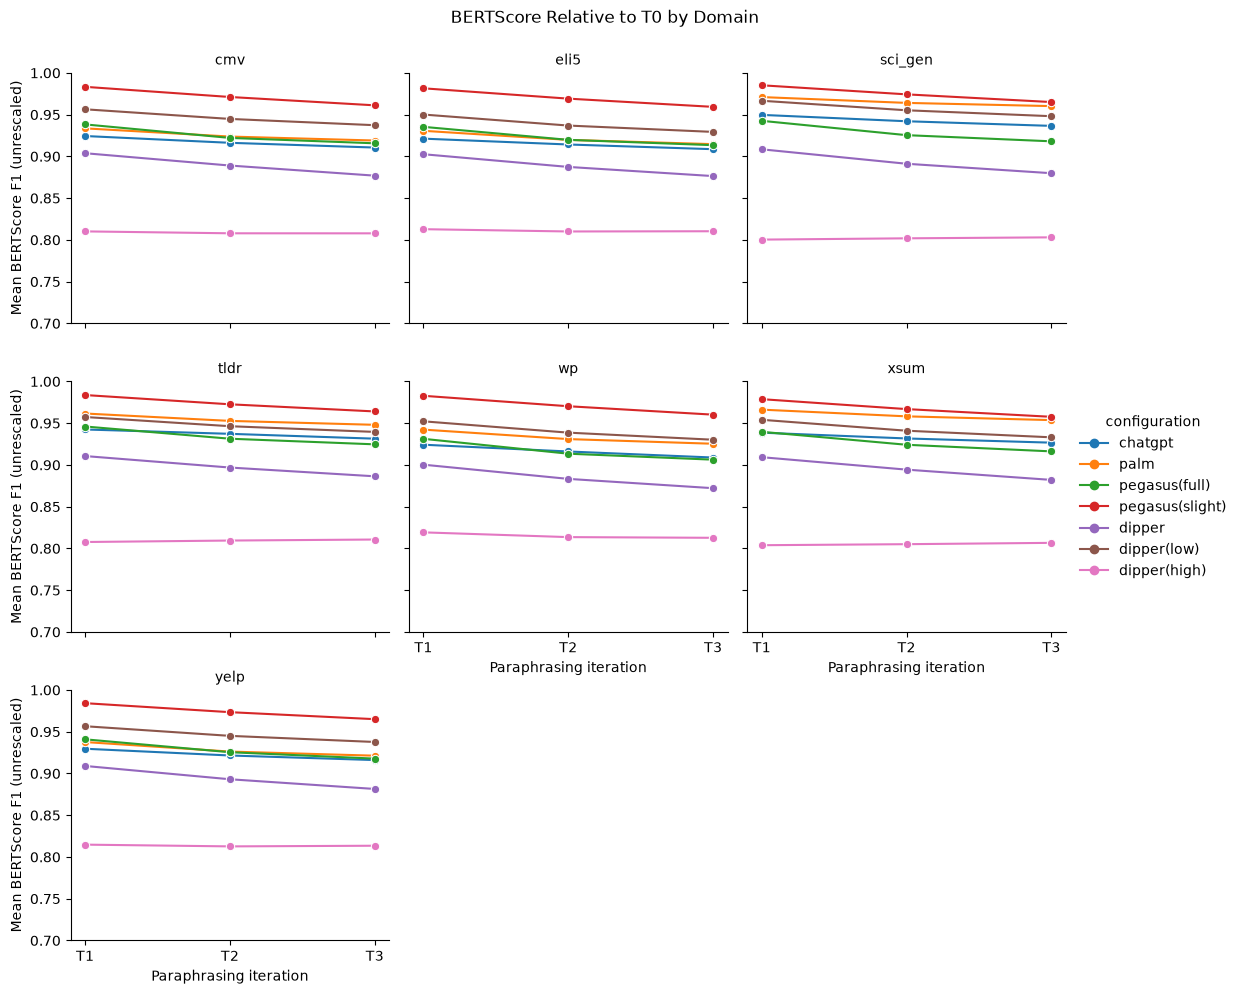

In [24]:
minimum = matched_baseline_by_domain["mean_BERTScore_F1"].min()
lower_limit = max(0, min(0.7, minimum - 0.02))

grid = sns.relplot(
    data=matched_baseline_by_domain,
    x="iteration",
    y="mean_BERTScore_F1",
    hue="configuration",
    hue_order=list(configuration_map),
    col="domain",
    col_order=sorted(bertscore_datasets),
    col_wrap=3,
    kind="line",
    marker="o",
    estimator=None,
    palette="tab10",
    height=3.2,
    aspect=1.15,
    facet_kws={"sharex": True, "sharey": True},
)

grid.set_titles("{col_name}")
grid.set_axis_labels(
    "Paraphrasing iteration",
    "Mean BERTScore F1 (unrescaled)",
)

for ax in grid.axes.flat:
    ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])
    ax.set_ylim(lower_limit, 1.0)

grid.figure.suptitle(
    "BERTScore Relative to T0 by Domain",
    y=1.03,
)

grid.figure.savefig(
    figures_dir / "06_bertscore_by_domain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [25]:
metric_columns = [
    "mean_ROUGEL_F1",
    "mean_BERTScore_F1",
]

t1 = (
    matched_baseline_by_domain.loc[
        matched_baseline_by_domain["iteration"].eq(1),
        ["domain", "configuration"] + metric_columns,
    ]
    .set_index(["domain", "configuration"])
)

t3 = (
    matched_baseline_by_domain.loc[
        matched_baseline_by_domain["iteration"].eq(3),
        ["domain", "configuration"] + metric_columns,
    ]
    .set_index(["domain", "configuration"])
)

change_table = pd.DataFrame(index=t1.index)

for metric, label in [
    ("mean_ROUGEL_F1", "ROUGEL"),
    ("mean_BERTScore_F1", "BERTScore"),
]:
    change_table[f"{label}_T1"] = t1[metric]
    change_table[f"{label}_T3"] = t3[metric]
    change_table[f"{label}_change"] = t3[metric] - t1[metric]

change_table = change_table.reset_index()

change_table.to_csv(
    bert_results_dir / "matched_T1_T3_changes.csv",
    index=False,
)

with pd.option_context("display.max_rows", None):
    display(change_table.round(4))

,domain,configuration,ROUGEL_T1,ROUGEL_T3,ROUGEL_change,BERTScore_T1,BERTScore_T3,BERTScore_change
0,cmv,chatgpt,0.4972,0.4146,-0.0826,0.9244,0.9106,-0.0138
1,cmv,dipper,0.3565,0.2450,-0.1115,0.9038,0.8769,-0.0269
2,cmv,dipper(high),0.1157,0.0824,-0.0332,0.8102,0.8078,-0.0023
3,cmv,dipper(low),0.7270,0.5904,-0.1366,0.9564,0.9374,-0.0190
4,cmv,palm,0.6048,0.5052,-0.0996,0.9336,0.9190,-0.0146
5,cmv,pegasus(full),0.6854,0.5560,-0.1294,0.9383,0.9157,-0.0226
6,cmv,pegasus(slight),0.9235,0.8091,-0.1144,0.9833,0.9611,-0.0222
7,eli5,chatgpt,0.4673,0.3935,-0.0737,0.9212,0.9086,-0.0126
8,eli5,dipper,0.3513,0.2415,-0.1099,0.9026,0.8764,-0.0262
9,eli5,dipper(high),0.1121,0.0790,-0.0331,0.8128,0.8103,-0.0025


In [26]:
matched_overall_rows = []

for configuration, versions in tqdm(
    configuration_versions.items(),
    total=len(configuration_versions),
    desc="Matched overall baseline",
):
    paraphraser, setting = configuration_map[configuration]

    for iteration, version in enumerate(versions, start=1):
        references = []
        candidates = []

        for wide in bertscore_datasets.values():
            references.extend(wide["original"].tolist())
            candidates.extend(wide[version].tolist())

        subset = matched_baseline_by_domain.loc[
            matched_baseline_by_domain["configuration"].eq(configuration)
            & matched_baseline_by_domain["iteration"].eq(iteration)
        ]

        pair_count = int(subset["pairs"].sum())
        assert pair_count == len(references) == len(candidates) == 12523

        result = {
            "paraphraser": paraphraser,
            "setting": setting,
            "configuration": configuration,
            "iteration": iteration,
            "pairs": pair_count,
            "corpus_BLEU": bleu_metric.corpus_score(
                candidates, [references]
            ).score,
        }

        for metric in [
            "mean_ROUGE1_F1",
            "mean_ROUGEL_F1",
            "mean_BERTScore_P",
            "mean_BERTScore_R",
            "mean_BERTScore_F1",
        ]:
            result[metric] = (
                subset[metric] * subset["pairs"]
            ).sum() / pair_count

        matched_overall_rows.append(result)

matched_baseline_overall = pd.DataFrame(matched_overall_rows)

matched_baseline_overall.to_csv(
    bert_results_dir / "matched_baseline_overall.csv",
    index=False,
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(matched_baseline_overall.round(4))

Matched overall baseline: 100%|██████████████████| 7/7 [01:11<00:00, 10.26s/it]


,paraphraser,setting,configuration,iteration,pairs,corpus_BLEU,mean_ROUGE1_F1,mean_ROUGEL_F1,mean_BERTScore_P,mean_BERTScore_R,mean_BERTScore_F1
0,ChatGPT,default,chatgpt,1,12523,27.4437,0.6241,0.5170,0.9374,0.9291,0.9331
1,ChatGPT,default,chatgpt,2,12523,24.6912,0.6068,0.4857,0.9305,0.9216,0.9260
2,ChatGPT,default,chatgpt,3,12523,21.1962,0.5677,0.4400,0.9251,0.9158,0.9203
3,PaLM,default,palm,1,12523,50.4834,0.7430,0.6798,0.9551,0.9437,0.9493
4,PaLM,default,palm,2,12523,42.7778,0.6878,0.6078,0.9461,0.9334,0.9396
5,PaLM,default,palm,3,12523,39.3553,0.6618,0.5735,0.9417,0.9283,0.9348
6,Pegasus,full,pegasus(full),1,12523,43.3399,0.7789,0.6733,0.9543,0.9259,0.9397
7,Pegasus,full,pegasus(full),2,12523,32.1109,0.6923,0.5859,0.9418,0.9073,0.9239
8,Pegasus,full,pegasus(full),3,12523,27.5952,0.6528,0.5399,0.9357,0.8991,0.9167
9,Pegasus,slight,pegasus(slight),1,12523,85.9171,0.9385,0.9133,0.9871,0.9781,0.9825


In [27]:
import spacy

nlp = spacy.load(
    "en_core_web_sm",
    disable=["ner"],
)

print(f"spaCy version: {spacy.__version__}")
print(f"Model: {nlp.meta['name']}")
print(f"Model version: {nlp.meta['version']}")
print(f"Active pipeline: {nlp.pipe_names}")

spaCy version: 3.8.16
Model: core_web_sm
Model version: 3.8.0
Active pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']


In [28]:
example_text = bertscore_datasets["cmv"].iloc[0]["original"]
example_doc = nlp(example_text)

first_sentence = next(example_doc.sents)

token_rows = []

for token in first_sentence:
    if token.is_space:
        continue

    token_rows.append({
        "token": token.text,
        "POS": token.pos_,
        "dependency": token.dep_,
        "head": token.head.text,
        "depth": len(list(token.ancestors)),
    })

print("First sentence:")
print(first_sentence.text)

display(pd.DataFrame(token_rows))

sentence_depth = max(
    len(list(token.ancestors))
    for token in first_sentence
    if not token.is_space and not token.is_punct
)

print(f"Sentence dependency depth: {sentence_depth}")

First sentence:
To me, this is the exact same issue, just a different year.


,token,POS,dependency,head,depth
0,To,ADP,prep,is,1
1,me,PRON,pobj,To,2
2,",",PUNCT,punct,is,1
3,this,PRON,nsubj,is,1
4,is,AUX,ROOT,is,0
5,the,DET,det,issue,2
6,exact,ADJ,amod,issue,2
7,same,ADJ,amod,issue,2
8,issue,NOUN,attr,is,1
9,",",PUNCT,punct,issue,2


Sentence dependency depth: 3


In [34]:
import numpy as np
from collections import Counter

pos_tags = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET",
    "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN",
    "SCONJ", "SYM", "VERB", "X", "PUNCT",
]

def extract_style_features(doc):
    tokens = [
        token for token in doc
        if not token.is_space and not token.is_punct
    ]

    sentence_lengths = []
    sentence_depths = []

    for sentence in doc.sents:
        sentence_tokens = [
            token for token in sentence
            if not token.is_space and not token.is_punct
        ]

        if not sentence_tokens:
            continue

        sentence_lengths.append(len(sentence_tokens))
        sentence_depths.append(
            max(
                len(list(token.ancestors))
                for token in sentence_tokens
            )
        )

    pos_counts = Counter(token.pos_ for token in tokens)
    token_count = len(tokens)

    mean_length = (
        float(np.mean(sentence_lengths))
        if sentence_lengths else np.nan
    )
    std_length = (
        float(np.std(sentence_lengths, ddof=0))
        if sentence_lengths else np.nan
    )

    features = {
        "token_count": token_count,
        "sentence_count": len(sentence_lengths),
        "mean_sentence_length": mean_length,
        "sentence_length_std": std_length,
        "sentence_length_cv": (
            std_length / mean_length
            if mean_length > 0 else np.nan
        ),
        "mean_dependency_depth": (
            float(np.mean(sentence_depths))
            if sentence_depths else np.nan
        ),
    }

    for tag in pos_tags:
        features[f"pos_{tag}"] = (
            pos_counts[tag] / token_count
            if token_count else np.nan
        )

    return features

example_features = extract_style_features(example_doc)

display(
    pd.Series(example_features, name="value")
    .to_frame()
    .round(4)
)

,value
token_count,190.0000
sentence_count,10.0000
mean_sentence_length,19.0000
sentence_length_std,9.6229
sentence_length_cv,0.5065
mean_dependency_depth,4.9000
pos_ADJ,0.0842
pos_ADP,0.0947
pos_ADV,0.0579
pos_AUX,0.0684


In [35]:
style_pilot_texts = []
style_pilot_metadata = []

for domain, wide in bertscore_datasets.items():
    sample = wide.sample(n=10, random_state=6120)

    for version in selected_versions:
        for (source, key), row in sample.iterrows():
            style_pilot_texts.append(row[version])
            style_pilot_metadata.append({
                "domain": domain,
                "source": source,
                "key": key,
                "version_name": version,
            })

start = perf_counter()
style_pilot_rows = []

docs = nlp.pipe(
    style_pilot_texts,
    batch_size=32,
    n_process=1,
    disable=["lemmatizer"],
)

for metadata, doc in tqdm(
    zip(style_pilot_metadata, docs),
    total=len(style_pilot_texts),
    desc="Style feature pilot",
):
    style_pilot_rows.append({
        **metadata,
        **extract_style_features(doc),
    })

style_pilot_features = pd.DataFrame(style_pilot_rows)
elapsed = perf_counter() - start

pos_columns = [f"pos_{tag}" for tag in pos_tags]

assert np.allclose(
    style_pilot_features[pos_columns].sum(axis=1),
    1.0,
)

display(style_pilot_features.head().round(4))
print(f"Texts processed: {len(style_pilot_features):,}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Texts per second: {len(style_pilot_features) / elapsed:.2f}")
print(
    "Texts with fewer than 2 sentences: "
    f"{style_pilot_features['sentence_count'].lt(2).sum():,}"
)

Style feature pilot: 100%|████████████████| 1540/1540 [00:11<00:00, 129.85it/s]


,domain,source,key,version_name,token_count,sentence_count,mean_sentence_length,sentence_length_std,sentence_length_cv,mean_dependency_depth,...,pos_NOUN,pos_NUM,pos_PART,pos_PRON,pos_PROPN,pos_SCONJ,pos_SYM,pos_VERB,pos_X,pos_PUNCT
0,cmv,BigScience,cmv-294,original,65,3,21.6667,11.4407,0.5280,5.3333,...,0.1385,0.0000,0.0462,0.1385,0.0462,0.0308,0.0,0.1231,0.0,0.0
1,cmv,PaLM,cmv-289,original,291,16,18.1875,3.3767,0.1857,5.4375,...,0.1546,0.0069,0.0962,0.1546,0.0000,0.0378,0.0,0.1581,0.0,0.0
2,cmv,LLAMA,cmv-277,original,90,7,12.8571,3.6812,0.2863,4.4286,...,0.1333,0.0444,0.0222,0.1667,0.0111,0.0111,0.0,0.1444,0.0,0.0
3,cmv,OpenAI,cmv-412,original,58,3,19.3333,4.0277,0.2083,5.0000,...,0.1552,0.0000,0.0172,0.2069,0.0172,0.0172,0.0,0.1552,0.0,0.0
4,cmv,Human,cmv-6667,original,216,16,13.5000,7.8740,0.5833,4.5000,...,0.1528,0.0046,0.0556,0.1343,0.0694,0.0231,0.0,0.1528,0.0,0.0


Texts processed: 1,540
Elapsed time: 11.87 seconds
Texts per second: 129.78
Texts with fewer than 2 sentences: 75


In [36]:
style_results_dir = (
    project_root / "experiments" / "style_features_spacy_v1"
)
style_results_dir.mkdir(parents=True, exist_ok=True)

style_chunk_size = 500
pos_columns = [f"pos_{tag}" for tag in pos_tags]

for domain, wide in bertscore_datasets.items():
    domain_dir = style_results_dir / domain
    domain_dir.mkdir(parents=True, exist_ok=True)

    for version in selected_versions:
        for start in tqdm(
            range(0, len(wide), style_chunk_size),
            desc=f"{domain} {version}",
        ):
            output_path = domain_dir / f"{version}_{start:05d}.csv"

            if output_path.exists():
                continue

            chunk = wide.iloc[start:start + style_chunk_size]
            identities = chunk.index.tolist()

            docs = nlp.pipe(
                chunk[version].tolist(),
                batch_size=32,
                n_process=1,
                disable=["lemmatizer"],
            )

            rows = []

            for (source, key), doc in zip(identities, docs):
                features = extract_style_features(doc)

                rows.append({
                    "domain": domain,
                    "source": source,
                    "key": key,
                    "version_name": version,
                    **features,
                    "single_sentence": features["sentence_count"] == 1,
                })

            output = pd.DataFrame(rows)

            assert len(output) == len(chunk)

            nonempty = output["token_count"].gt(0)
            assert np.allclose(
                output.loc[nonempty, pos_columns].sum(axis=1),
                1.0,
            )

            temporary_path = output_path.with_suffix(".tmp")
            output.to_csv(temporary_path, index=False)
            temporary_path.replace(output_path)

print("Style feature extraction complete")

cmv pegasus(full)_pegasus(full): 100%|███████████| 2/2 [00:07<00:00,  3.67s/it]
cmv pegasus(full)_pegasus(full)_pegasus(full): 100%|█| 2/2 [00:06<00:00,  3.47s
cmv pegasus(slight)_pegasus(slight): 100%|███████| 2/2 [00:09<00:00,  4.79s/it]
cmv pegasus(slight)_pegasus(slight)_pegasus(slight): 100%|█| 2/2 [00:09<00:00, 
cmv dipper(high)_dipper(high): 100%|█████████████| 2/2 [00:05<00:00,  2.56s/it]
cmv dipper(high)_dipper(high)_dipper(high): 100%|█| 2/2 [00:03<00:00,  1.83s/it
eli5 pegasus(full)_pegasus(full): 100%|██████████| 5/5 [00:13<00:00,  2.72s/it]
eli5 pegasus(full)_pegasus(full)_pegasus(full): 100%|█| 5/5 [00:13<00:00,  2.65
eli5 pegasus(slight)_pegasus(slight): 100%|██████| 5/5 [00:17<00:00,  3.59s/it]
eli5 pegasus(slight)_pegasus(slight)_pegasus(slight): 100%|█| 5/5 [00:17<00:00,
eli5 dipper(high)_dipper(high): 100%|████████████| 5/5 [00:10<00:00,  2.01s/it]
eli5 dipper(high)_dipper(high)_dipper(high): 100%|█| 5/5 [00:07<00:00,  1.48s/i
sci_gen pegasus(full)_pegasus(full): 100

Style feature extraction complete


In [37]:
style_frames = []

for domain in bertscore_datasets:
    for path in sorted((style_results_dir / domain).glob("*.csv")):
        style_frames.append(
            pd.read_csv(
                path,
                dtype={"source": str, "key": str},
                keep_default_na=False,
                na_values=[""],
            )
        )

style_features = pd.concat(style_frames, ignore_index=True)

identity_columns = ["domain", "source", "key", "version_name"]

assert not style_features.duplicated(identity_columns).any()
assert len(style_features) == 275506

for domain, wide in bertscore_datasets.items():
    expected_ids = set(wide.index)
    domain_features = style_features.loc[
        style_features["domain"].eq(domain)
    ]

    for version in selected_versions:
        subset = domain_features.loc[
            domain_features["version_name"].eq(version)
        ]

        actual_ids = set(zip(subset["source"], subset["key"]))
        assert actual_ids == expected_ids, (
            f"Sample mismatch: {domain}, {version}"
        )

nonempty = style_features["token_count"].gt(0)

assert np.allclose(
    style_features.loc[nonempty, pos_columns].sum(axis=1),
    1.0,
)

style_audit = (
    style_features.groupby("domain")
    .agg(
        texts=("version_name", "size"),
        versions=("version_name", "nunique"),
        zero_token_texts=("token_count", lambda values: values.eq(0).sum()),
        single_sentence_texts=(
            "sentence_count",
            lambda values: values.eq(1).sum(),
        ),
    )
)

display(style_audit)

style_audit.to_csv(style_results_dir / "style_feature_audit.csv")

print(f"Verified texts: {len(style_features):,}")
print("All sample identities and POS proportions verified")

,texts,versions,zero_token_texts,single_sentence_texts
domain,,,,
cmv,19734,22,0,452
eli5,49918,22,0,3167
sci_gen,28336,22,0,855
tldr,44286,22,0,2466
wp,23210,22,0,428
xsum,52954,22,0,2964
yelp,57068,22,0,2552


Verified texts: 275,506
All sample identities and POS proportions verified


In [38]:
style_keys = ["domain", "source", "key"]

original_features = (
    style_features.loc[
        style_features["version_name"].eq("original")
    ]
    .set_index(style_keys)
)

style_delta_frames = []

for configuration, versions in configuration_versions.items():
    for iteration, version in enumerate(versions, start=1):
        rewritten = (
            style_features.loc[
                style_features["version_name"].eq(version)
            ]
            .set_index(style_keys)
            .reindex(original_features.index)
        )

        assert rewritten["token_count"].notna().all()

        delta = original_features.index.to_frame(index=False)
        delta["configuration"] = configuration
        delta["iteration"] = iteration

        original_pos = original_features[pos_columns].to_numpy()
        rewritten_pos = rewritten[pos_columns].to_numpy()

        # Total variation distance between POS distributions.
        delta["pos_distance"] = (
            0.5 * np.abs(rewritten_pos - original_pos).sum(axis=1)
        )

        for feature in [
            "mean_sentence_length",
            "mean_dependency_depth",
        ]:
            delta[f"{feature}_change"] = (
                rewritten[feature].to_numpy()
                - original_features[feature].to_numpy()
            )

        cv_valid = (
            original_features["sentence_count"].ge(2)
            & rewritten["sentence_count"].ge(2)
        ).to_numpy()

        cv_change = (
            rewritten["sentence_length_cv"].to_numpy()
            - original_features["sentence_length_cv"].to_numpy()
        )

        delta["sentence_length_cv_change"] = np.where(
            cv_valid, cv_change, np.nan
        )
        delta["cv_pair_valid"] = cv_valid

        style_delta_frames.append(delta)

style_pair_deltas = pd.concat(style_delta_frames, ignore_index=True)

assert len(style_pair_deltas) == 262983

style_delta_by_domain = (
    style_pair_deltas.groupby(
        ["domain", "configuration", "iteration"]
    )
    .agg(
        pairs=("pos_distance", "size"),
        mean_pos_distance=("pos_distance", "mean"),
        mean_sentence_length_change=(
            "mean_sentence_length_change", "mean"
        ),
        mean_dependency_depth_change=(
            "mean_dependency_depth_change", "mean"
        ),
        mean_sentence_length_cv_change=(
            "sentence_length_cv_change", "mean"
        ),
        cv_valid_pairs=("cv_pair_valid", "sum"),
    )
    .reset_index()
)

style_pair_deltas.to_csv(
    style_results_dir / "style_pair_deltas.csv",
    index=False,
)
style_delta_by_domain.to_csv(
    style_results_dir / "style_delta_by_domain.csv",
    index=False,
)

display(style_delta_by_domain.round(4))
print(f"Style comparison pairs: {len(style_pair_deltas):,}")
print(f"Summary rows: {len(style_delta_by_domain)}")

,domain,configuration,iteration,pairs,mean_pos_distance,mean_sentence_length_change,mean_dependency_depth_change,mean_sentence_length_cv_change,cv_valid_pairs
0,cmv,chatgpt,1,897,0.1064,-1.7345,0.1642,-0.1360,894
1,cmv,chatgpt,2,897,0.1162,-1.7196,0.2117,-0.1514,894
2,cmv,chatgpt,3,897,0.1226,-1.7598,0.2245,-0.1567,893
3,cmv,dipper,1,897,0.1082,-0.0423,-0.1280,-0.0072,892
4,cmv,dipper,2,897,0.1280,-0.6776,-0.2821,-0.0139,891
...,...,...,...,...,...,...,...,...,...
142,yelp,pegasus(full),2,2594,0.1450,-3.2643,-0.6666,0.0016,2534
143,yelp,pegasus(full),3,2594,0.1635,-3.3114,-0.7540,0.0226,2531
144,yelp,pegasus(slight),1,2594,0.0405,-0.5787,-0.0894,0.0016,2537
145,yelp,pegasus(slight),2,2594,0.0606,-1.0141,-0.1640,0.0011,2537


Style comparison pairs: 262,983
Summary rows: 147


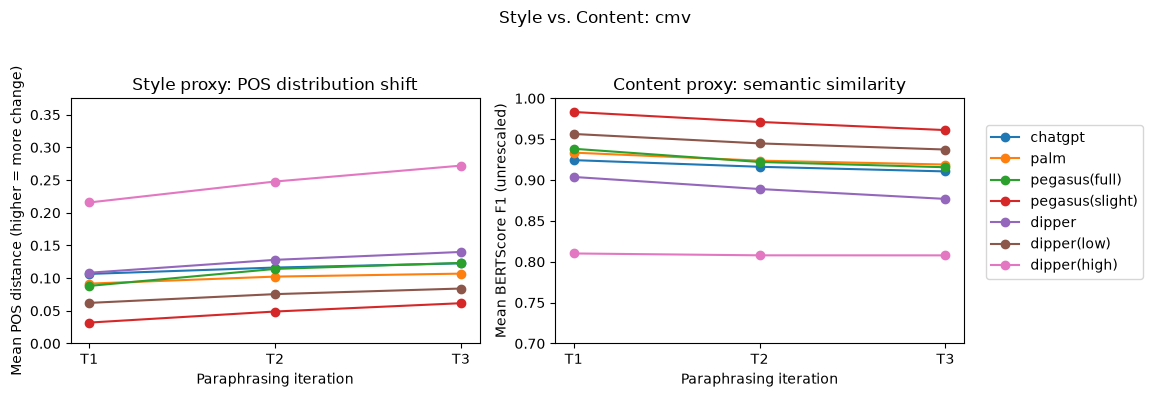

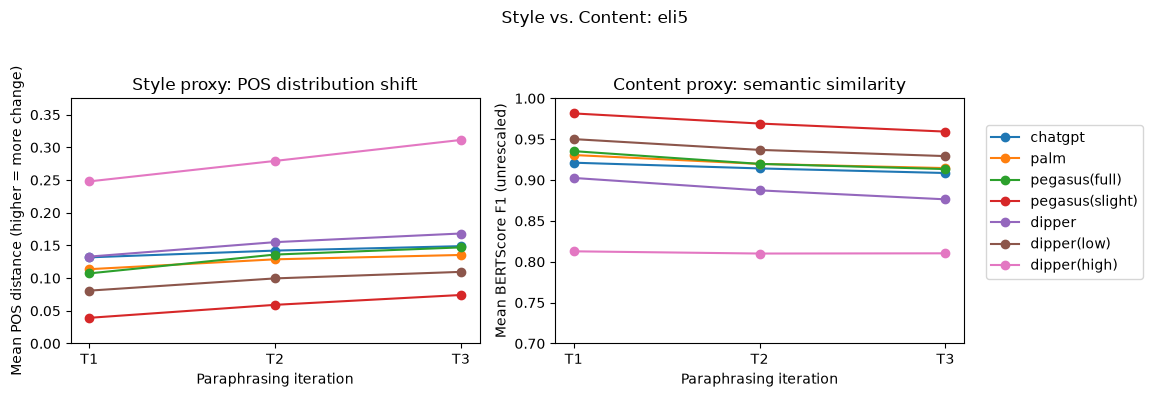

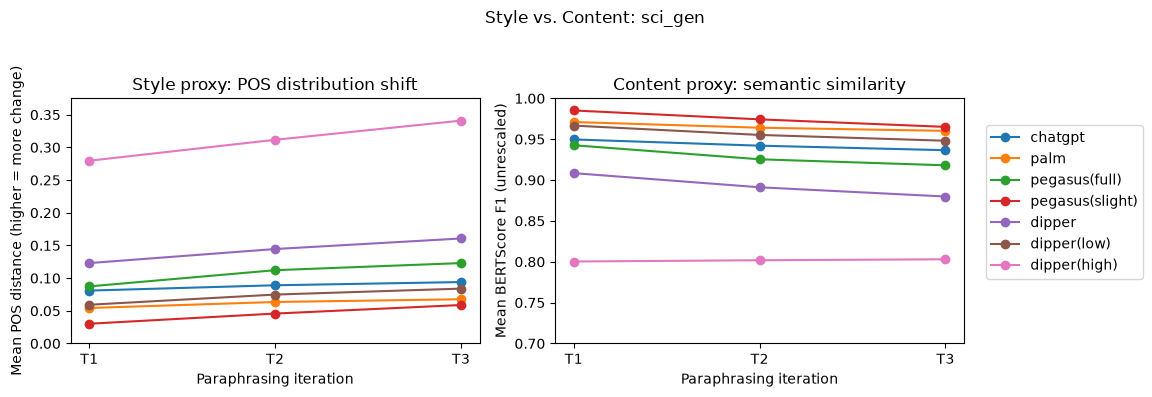

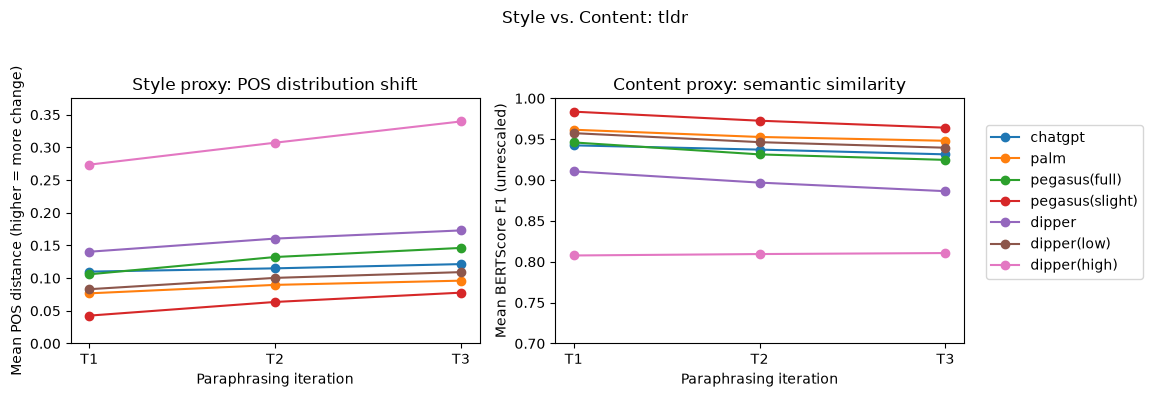

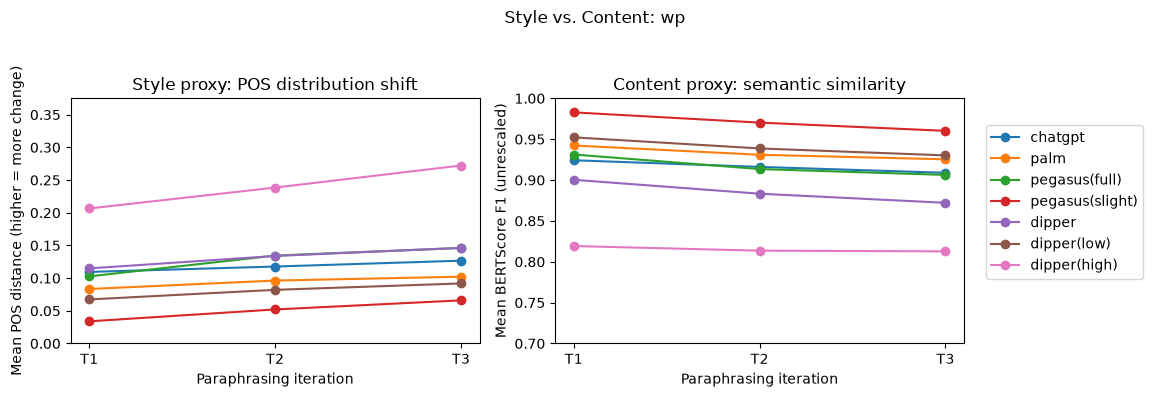

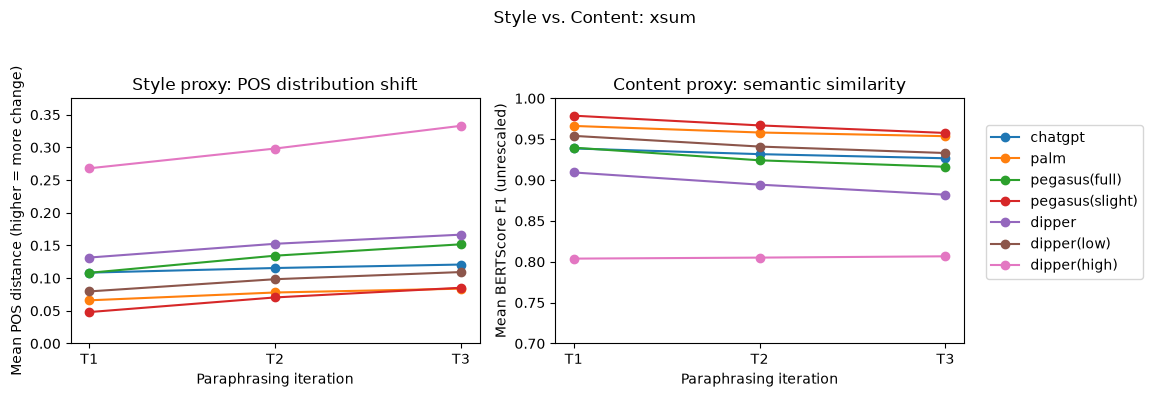

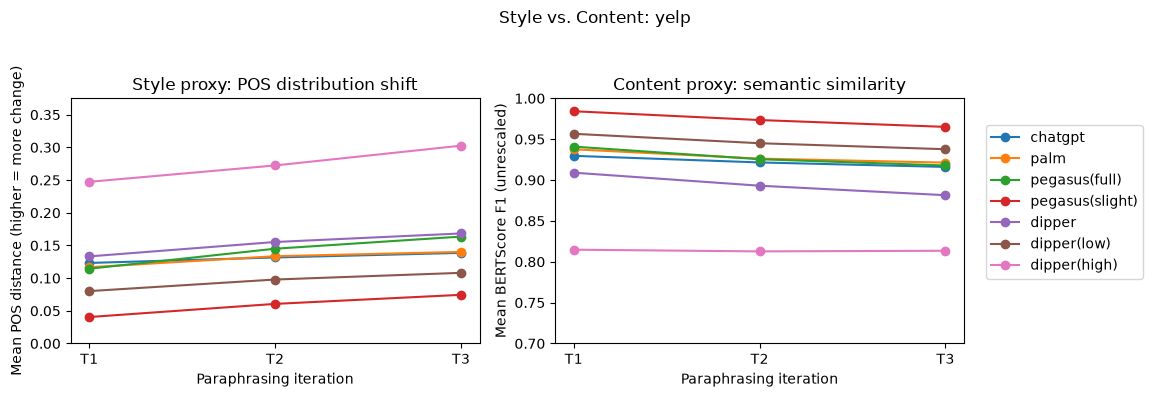

In [39]:
style_content_by_domain = style_delta_by_domain.merge(
    matched_baseline_by_domain[
        [
            "domain", "configuration", "iteration",
            "pairs", "mean_BERTScore_F1",
        ]
    ],
    on=["domain", "configuration", "iteration", "pairs"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert style_content_by_domain["_merge"].eq("both").all()

style_content_by_domain = style_content_by_domain.drop(
    columns="_merge"
)

style_content_by_domain.to_csv(
    style_results_dir / "style_content_by_domain.csv",
    index=False,
)

configuration_colors = dict(zip(
    configuration_map,
    sns.color_palette("tab10", len(configuration_map)),
))

pos_upper = min(
    1.0,
    max(0.2, style_content_by_domain["mean_pos_distance"].max() * 1.1),
)

bert_lower = max(
    0.0,
    min(0.7, style_content_by_domain["mean_BERTScore_F1"].min() - 0.02),
)

for domain in sorted(bertscore_datasets):
    subset = style_content_by_domain.loc[
        style_content_by_domain["domain"].eq(domain)
    ]

    fig, axes = plt.subplots(figsize=(12, 4), ncols=2)

    for configuration, color in configuration_colors.items():
        values = subset.loc[
            subset["configuration"].eq(configuration)
        ].sort_values("iteration")

        axes[0].plot(
            values["iteration"],
            values["mean_pos_distance"],
            marker="o",
            color=color,
            label=configuration,
        )

        axes[1].plot(
            values["iteration"],
            values["mean_BERTScore_F1"],
            marker="o",
            color=color,
        )

    axes[0].set_title("Style proxy: POS distribution shift")
    axes[0].set_ylabel("Mean POS distance (higher = more change)")
    axes[0].set_ylim(0, pos_upper)

    axes[1].set_title("Content proxy: semantic similarity")
    axes[1].set_ylabel("Mean BERTScore F1 (unrescaled)")
    axes[1].set_ylim(bert_lower, 1)

    for ax in axes:
        ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])
        ax.set_xlabel("Paraphrasing iteration")

    fig.suptitle(f"Style vs. Content: {domain}")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="center left",
        bbox_to_anchor=(0.82, 0.5),
    )

    fig.tight_layout(rect=[0, 0, 0.82, 0.93])

    fig.savefig(
        figures_dir / f"07_style_content_{domain}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [40]:
pos_trends = style_delta_by_domain.pivot(
    index=["domain", "configuration"],
    columns="iteration",
    values="mean_pos_distance",
)

pos_trends.columns = ["POS_T1", "POS_T2", "POS_T3"]

pos_trends["T1_to_T2_change"] = (
    pos_trends["POS_T2"] - pos_trends["POS_T1"]
)
pos_trends["T2_to_T3_change"] = (
    pos_trends["POS_T3"] - pos_trends["POS_T2"]
)

increasing = (
    pos_trends["T1_to_T2_change"].gt(0)
    & pos_trends["T2_to_T3_change"].gt(0)
)

print(f"Strictly increasing POS-distance trends: {increasing.sum()}/49")
display(pos_trends.loc[~increasing].round(4))

pos_trends.to_csv(style_results_dir / "pos_distance_trends.csv")

Strictly increasing POS-distance trends: 49/49


,,POS_T1,POS_T2,POS_T3,T1_to_T2_change,T2_to_T3_change
domain,configuration,,,,,


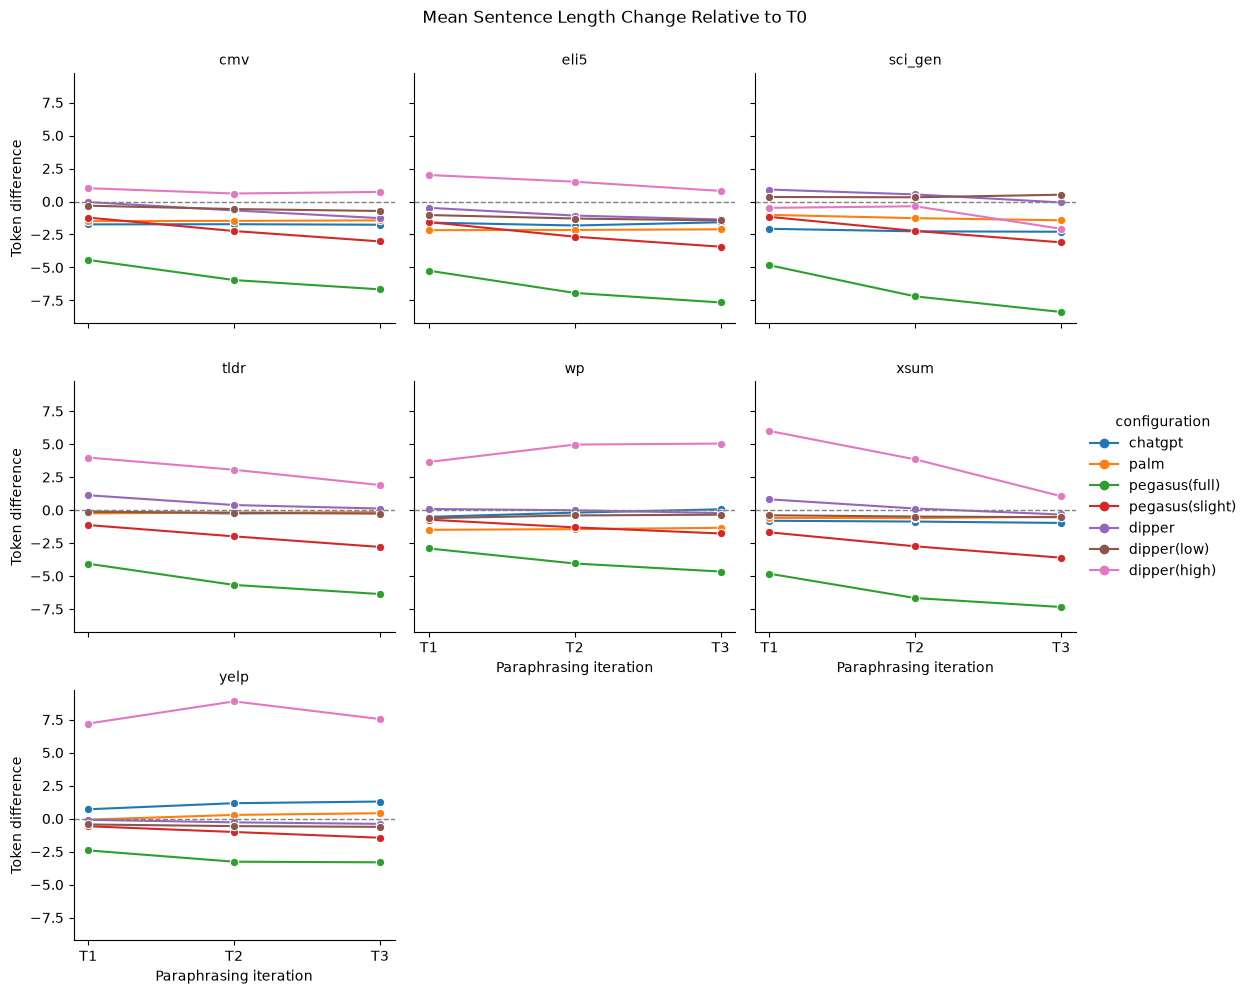

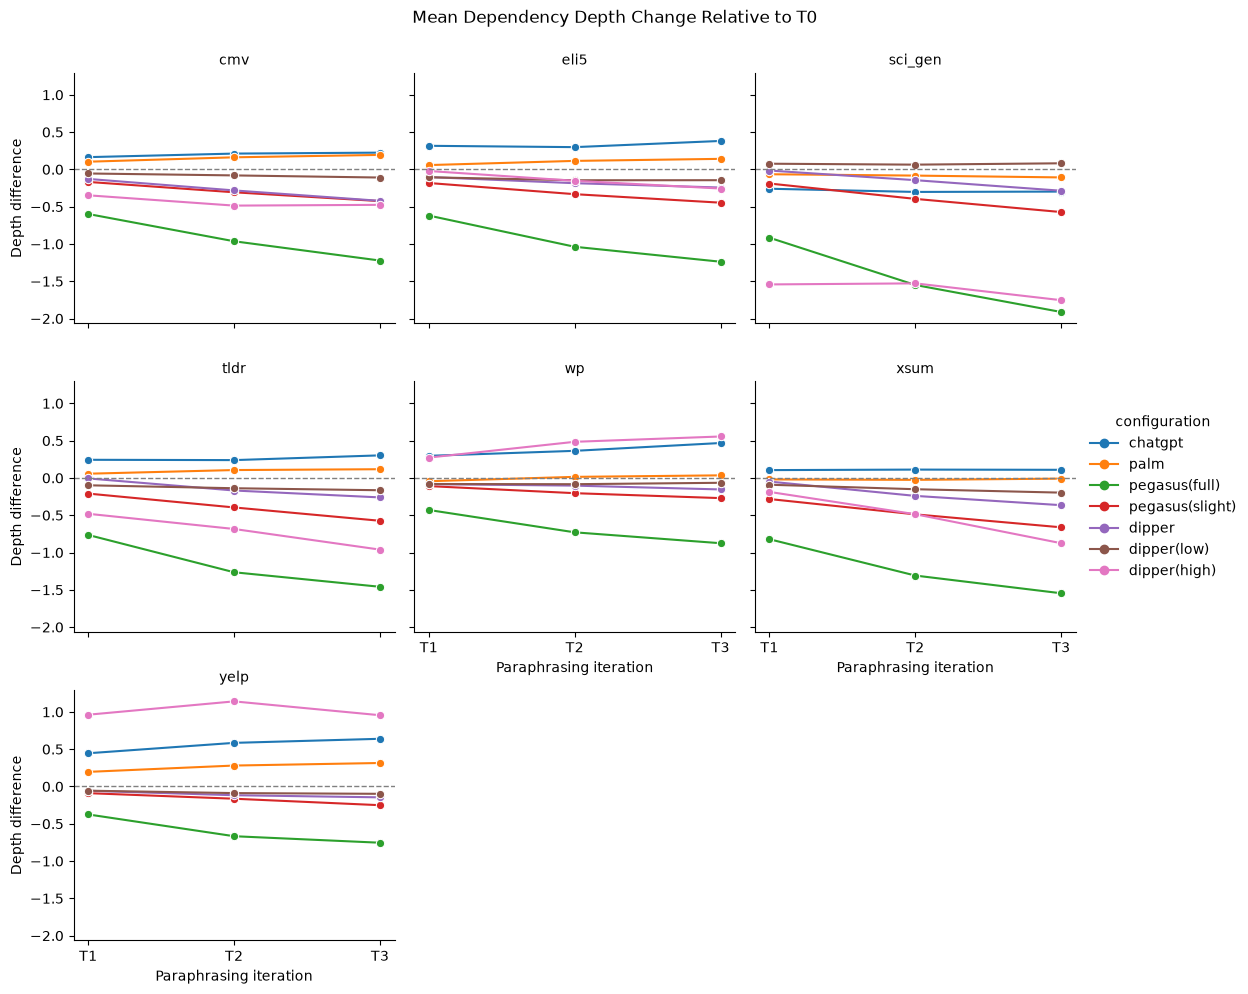

In [41]:
structural_metrics = {
    "mean_sentence_length_change": (
        "Mean Sentence Length Change Relative to T0",
        "Token difference",
        "08_sentence_length_change_by_domain.png",
    ),
    "mean_dependency_depth_change": (
        "Mean Dependency Depth Change Relative to T0",
        "Depth difference",
        "09_dependency_depth_change_by_domain.png",
    ),
}

for metric, (title, ylabel, filename) in structural_metrics.items():
    grid = sns.relplot(
        data=style_delta_by_domain,
        x="iteration",
        y=metric,
        hue="configuration",
        hue_order=list(configuration_map),
        col="domain",
        col_order=sorted(bertscore_datasets),
        col_wrap=3,
        kind="line",
        marker="o",
        estimator=None,
        palette="tab10",
        height=3.2,
        aspect=1.15,
        facet_kws={"sharex": True, "sharey": True},
    )

    grid.set_titles("{col_name}")
    grid.set_axis_labels("Paraphrasing iteration", ylabel)

    for ax in grid.axes.flat:
        ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])
        ax.axhline(0, color="gray", linestyle="--", linewidth=1)

    grid.figure.suptitle(title, y=1.03)

    grid.figure.savefig(
        figures_dir / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [43]:
import sentence_transformers
import torch

print(f"Sentence Transformers: {sentence_transformers.__version__}")
print(f"MPS available: {torch.backends.mps.is_available()}")

Sentence Transformers: 6.1.0
MPS available: True


In [45]:
from sentence_transformers import SentenceTransformer
from time import perf_counter

sbert_model_name = "sentence-transformers/all-mpnet-base-v2"
sbert_device = "mps" if torch.backends.mps.is_available() else "cpu"

start = perf_counter()

sbert_model = SentenceTransformer(
    sbert_model_name,
    device=sbert_device,
)

print(f"Model: {sbert_model_name}")
print(f"Device: {sbert_device}")
print(f"Maximum sequence length: {sbert_model.max_seq_length}")
print(f"Embedding dimension: {sbert_model.get_sentence_embedding_dimension()}")
print(f"Loaded in {perf_counter() - start:.2f} seconds")

Loading weights: 100%|████████████████████| 199/199 [00:00<00:00, 12556.85it/s]


Model: sentence-transformers/all-mpnet-base-v2
Device: mps
Maximum sequence length: 384
Embedding dimension: 768
Loaded in 2.04 seconds


/var/folders/7y/bydzm2md4czg993nxdgs4gnc0000gn/T/ipykernel_34919/1947584040.py:17: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Embedding dimension: {sbert_model.get_sentence_embedding_dimension()}")


In [46]:
sbert_token_lengths = {}
sbert_coverage_rows = []
sbert_token_limit = sbert_model.max_seq_length

for domain, wide in tqdm(
    bertscore_datasets.items(),
    total=len(bertscore_datasets),
    desc="Checking SBERT token lengths",
):
    lengths_table = pd.DataFrame(index=wide.index)

    for version in selected_versions:
        texts = wide[version].tolist()
        lengths = []

        for start in range(0, len(texts), 128):
            encoded = sbert_model.tokenizer(
                texts[start:start + 128],
                add_special_tokens=True,
                truncation=False,
                padding=False,
                return_length=True,
                verbose=False,
            )
            lengths.extend(encoded["length"])

        lengths_table[version] = lengths

    sbert_token_lengths[domain] = lengths_table
    fits_all = lengths_table.le(sbert_token_limit).all(axis=1)

    sbert_coverage_rows.append({
        "domain": domain,
        "current_originals": len(wide),
        "all_versions_within_limit": int(fits_all.sum()),
        "chains_with_overlong_versions": int((~fits_all).sum()),
        "retained_pct": 100 * fits_all.mean(),
        "maximum_tokens": int(lengths_table.max().max()),
    })

sbert_coverage_table = pd.DataFrame(
    sbert_coverage_rows
).set_index("domain")

display(sbert_coverage_table.round(2))
print(
    "Total chains within SBERT limit: "
    f"{sbert_coverage_table['all_versions_within_limit'].sum():,}"
)

sbert_coverage_table.to_csv(
    metadata_dir / "sbert_length_coverage.csv"
)

Checking SBERT token lengths: 100%|██████████████| 7/7 [00:10<00:00,  1.49s/it]


,current_originals,all_versions_within_limit,chains_with_overlong_versions,retained_pct,maximum_tokens
domain,,,,,
cmv,897,717,180,79.93,591
eli5,2269,2011,258,88.63,619
sci_gen,1288,1207,81,93.71,618
tldr,2013,1847,166,91.75,525
wp,1055,877,178,83.13,594
xsum,2407,2102,305,87.33,612
yelp,2594,2364,230,91.13,1975


Total chains within SBERT limit: 11,125


In [47]:
sbert_datasets = {}
sbert_manifest_frames = []

for domain, wide in bertscore_datasets.items():
    fits_all = (
        sbert_token_lengths[domain]
        .le(sbert_token_limit)
        .all(axis=1)
    )

    sbert_datasets[domain] = wide.loc[fits_all].copy()

    manifest = (
        sbert_datasets[domain]
        .index.to_frame(index=False)
    )
    manifest.insert(0, "domain", domain)
    sbert_manifest_frames.append(manifest)

sbert_sample_manifest = pd.concat(
    sbert_manifest_frames,
    ignore_index=True,
)

assert len(sbert_sample_manifest) == 11125
assert not sbert_sample_manifest.duplicated(
    ["domain", "source", "key"]
).any()

sbert_sample_manifest.to_csv(
    metadata_dir / "sbert_sample_manifest.csv",
    index=False,
)

display(
    sbert_sample_manifest.groupby("domain")
    .size()
    .rename("originals")
    .to_frame()
)

print(f"SBERT originals: {len(sbert_sample_manifest):,}")
print(f"SBERT comparison pairs: {len(sbert_sample_manifest) * 21:,}")

,originals
domain,
cmv,717
eli5,2011
sci_gen,1207
tldr,1847
wp,877
xsum,2102
yelp,2364


SBERT originals: 11,125
SBERT comparison pairs: 233,625


In [48]:
import numpy as np

sbert_pilot_references = []
sbert_pilot_candidates = []

for domain, wide in sbert_datasets.items():
    sample = wide.sample(n=20, random_state=6120)

    sbert_pilot_references.extend(sample["original"].tolist())
    sbert_pilot_candidates.extend(sample["chatgpt"].tolist())

start = perf_counter()

pilot_embeddings = sbert_model.encode(
    sbert_pilot_references + sbert_pilot_candidates,
    batch_size=8,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True,
)

pair_count = len(sbert_pilot_references)

reference_embeddings = pilot_embeddings[:pair_count]
candidate_embeddings = pilot_embeddings[pair_count:]

pilot_cosines = np.sum(
    reference_embeddings * candidate_embeddings,
    axis=1,
)

elapsed = perf_counter() - start

assert np.isfinite(pilot_cosines).all()

print(f"Pilot pairs: {pair_count}")
print(f"Texts encoded: {len(pilot_embeddings)}")
print(f"Mean SBERT cosine: {pilot_cosines.mean():.4f}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Texts per second: {len(pilot_embeddings) / elapsed:.2f}")

Batches: 100%|█████████████████████████████████| 35/35 [00:10<00:00,  3.23it/s]

Pilot pairs: 140
Texts encoded: 280
Mean SBERT cosine: 0.9105
Elapsed time: 10.83 seconds
Texts per second: 25.85


In [49]:
sbert_results_dir = (
    project_root / "experiments" / "sbert_mpnet_384_v1"
)
sbert_results_dir.mkdir(parents=True, exist_ok=True)

sbert_chunk_size = 500

def load_or_encode_version(domain, wide, version):
    embedding_dir = sbert_results_dir / domain / "embeddings"
    embedding_dir.mkdir(parents=True, exist_ok=True)

    embedding_chunks = []

    for start in tqdm(
        range(0, len(wide), sbert_chunk_size),
        desc=f"{domain} {version}",
    ):
        chunk = wide.iloc[start:start + sbert_chunk_size]
        path = embedding_dir / f"{version}_{start:05d}.npz"

        sources = chunk.index.get_level_values("source").to_numpy(dtype=str)
        keys = chunk.index.get_level_values("key").to_numpy(dtype=str)

        if path.exists():
            with np.load(path, allow_pickle=False) as saved:
                assert np.array_equal(saved["sources"], sources)
                assert np.array_equal(saved["keys"], keys)
                embeddings = saved["embeddings"]
        else:
            embeddings = sbert_model.encode(
                chunk[version].tolist(),
                batch_size=8,
                normalize_embeddings=True,
                convert_to_numpy=True,
                show_progress_bar=False,
            )

            temporary_path = path.with_suffix(".tmp")

            with temporary_path.open("wb") as file:
                np.savez_compressed(
                    file,
                    sources=sources,
                    keys=keys,
                    embeddings=embeddings,
                )

            temporary_path.replace(path)

        assert len(embeddings) == len(chunk)
        assert np.isfinite(embeddings).all()
        embedding_chunks.append(embeddings)

    return np.concatenate(embedding_chunks, axis=0)


for domain, wide in sbert_datasets.items():
    original_embeddings = load_or_encode_version(
        domain, wide, "original"
    )

    domain_rows = []

    for configuration, versions in configuration_versions.items():
        for iteration, version in enumerate(versions, start=1):
            rewritten_embeddings = load_or_encode_version(
                domain, wide, version
            )

            cosines = np.sum(
                original_embeddings * rewritten_embeddings,
                axis=1,
            )

            output = wide.index.to_frame(index=False)
            output.insert(0, "domain", domain)
            output["configuration"] = configuration
            output["iteration"] = iteration
            output["SBERT_cosine"] = cosines

            domain_rows.append(output)

    domain_scores = pd.concat(domain_rows, ignore_index=True)

    assert len(domain_scores) == len(wide) * 21

    output_path = sbert_results_dir / f"{domain}_pair_scores.csv"
    temporary_path = output_path.with_suffix(".tmp")

    domain_scores.to_csv(temporary_path, index=False)
    temporary_path.replace(output_path)

print("SBERT evaluation complete")

cmv pegasus(full)_pegasus(full): 100%|███████████| 2/2 [00:10<00:00,  5.49s/it]
cmv pegasus(full)_pegasus(full)_pegasus(full): 100%|█| 2/2 [00:10<00:00,  5.23s
cmv pegasus(slight)_pegasus(slight): 100%|███████| 2/2 [00:15<00:00,  7.78s/it]
cmv pegasus(slight)_pegasus(slight)_pegasus(slight): 100%|█| 2/2 [00:14<00:00, 
cmv dipper(high)_dipper(high): 100%|█████████████| 2/2 [00:08<00:00,  4.24s/it]
cmv dipper(high)_dipper(high)_dipper(high): 100%|█| 2/2 [00:06<00:00,  3.11s/it
eli5 pegasus(full)_pegasus(full): 100%|██████████| 5/5 [00:30<00:00,  6.19s/it]
eli5 pegasus(full)_pegasus(full)_pegasus(full): 100%|█| 5/5 [00:27<00:00,  5.55
eli5 pegasus(slight)_pegasus(slight): 100%|██████| 5/5 [00:39<00:00,  7.92s/it]
eli5 pegasus(slight)_pegasus(slight)_pegasus(slight): 100%|█| 5/5 [00:38<00:00,
eli5 dipper(high)_dipper(high): 100%|████████████| 5/5 [00:23<00:00,  4.60s/it]
eli5 dipper(high)_dipper(high)_dipper(high): 100%|█| 5/5 [00:18<00:00,  3.62s/i
sci_gen pegasus(full)_pegasus(full): 100

SBERT evaluation complete


In [50]:
sbert_pair_scores = pd.concat(
    [
        pd.read_csv(
            sbert_results_dir / f"{domain}_pair_scores.csv",
            dtype={"source": str, "key": str},
            keep_default_na=False,
        )
        for domain in sbert_datasets
    ],
    ignore_index=True,
)

identity_columns = [
    "domain", "source", "key", "configuration", "iteration"
]

assert len(sbert_pair_scores) == 233625
assert not sbert_pair_scores.duplicated(identity_columns).any()
assert np.isfinite(sbert_pair_scores["SBERT_cosine"]).all()
assert sbert_pair_scores["SBERT_cosine"].between(
    -1.00001, 1.00001
).all()

for domain, wide in sbert_datasets.items():
    expected_ids = set(wide.index)

    for configuration in configuration_versions:
        for iteration in range(1, 4):
            subset = sbert_pair_scores.loc[
                sbert_pair_scores["domain"].eq(domain)
                & sbert_pair_scores["configuration"].eq(configuration)
                & sbert_pair_scores["iteration"].eq(iteration)
            ]

            actual_ids = set(zip(subset["source"], subset["key"]))
            assert actual_ids == expected_ids
            assert len(subset) == len(wide)

sbert_by_domain = (
    sbert_pair_scores.groupby(
        ["domain", "configuration", "iteration"]
    )
    .agg(
        pairs=("SBERT_cosine", "size"),
        mean_SBERT_cosine=("SBERT_cosine", "mean"),
    )
    .reset_index()
)

sbert_by_domain.to_csv(
    sbert_results_dir / "sbert_by_domain.csv",
    index=False,
)

display(sbert_by_domain.round(4))
print(f"Verified pairs: {len(sbert_pair_scores):,}")
print(f"Summary rows: {len(sbert_by_domain)}")
print("All SBERT sample identities verified")

,domain,configuration,iteration,pairs,mean_SBERT_cosine
0,cmv,chatgpt,1,717,0.8922
1,cmv,chatgpt,2,717,0.8718
2,cmv,chatgpt,3,717,0.8586
3,cmv,dipper,1,717,0.8100
4,cmv,dipper,2,717,0.7654
...,...,...,...,...,...
142,yelp,pegasus(full),2,2364,0.8631
143,yelp,pegasus(full),3,2364,0.8453
144,yelp,pegasus(slight),1,2364,0.9759
145,yelp,pegasus(slight),2,2364,0.9571


Verified pairs: 233,625
Summary rows: 147
All SBERT sample identities verified


In [51]:
four_metric_rows = []

for domain, wide in tqdm(
    sbert_datasets.items(),
    total=len(sbert_datasets),
    desc="Four-metric matched baseline",
):
    sample_ids = wide.index.to_frame(index=False)

    lexical_scores = pd.read_csv(
        results_dir / f"{domain}_pair_scores.csv",
        dtype={"source": str, "key": str},
        keep_default_na=False,
    ).merge(
        sample_ids,
        on=["source", "key"],
        how="inner",
        validate="many_to_one",
    )

    bert_scores = bert_pair_scores.loc[
        bert_pair_scores["domain"].eq(domain)
    ].merge(
        sample_ids,
        on=["source", "key"],
        how="inner",
        validate="many_to_one",
    )

    assert len(lexical_scores) == len(bert_scores) == len(wide) * 21

    for configuration, versions in configuration_versions.items():
        for iteration, version in enumerate(versions, start=1):
            lexical = lexical_scores.loc[
                lexical_scores["configuration"].eq(configuration)
                & lexical_scores["iteration"].eq(iteration)
            ]

            bert = bert_scores.loc[
                bert_scores["configuration"].eq(configuration)
                & bert_scores["iteration"].eq(iteration)
            ]

            assert len(lexical) == len(bert) == len(wide)

            four_metric_rows.append({
                "domain": domain,
                "configuration": configuration,
                "iteration": iteration,
                "pairs": len(wide),
                "corpus_BLEU": bleu_metric.corpus_score(
                    wide[version].tolist(),
                    [wide["original"].tolist()],
                ).score,
                "mean_ROUGE1_F1": lexical["ROUGE-1_F1"].mean(),
                "mean_ROUGEL_F1": lexical["ROUGE-L_F1"].mean(),
                "mean_BERTScore_P": bert["BERTScore_P"].mean(),
                "mean_BERTScore_R": bert["BERTScore_R"].mean(),
                "mean_BERTScore_F1": bert["BERTScore_F1"].mean(),
            })

four_metric_by_domain = pd.DataFrame(four_metric_rows).merge(
    sbert_by_domain,
    on=["domain", "configuration", "iteration", "pairs"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert four_metric_by_domain["_merge"].eq("both").all()

four_metric_by_domain = four_metric_by_domain.drop(columns="_merge")

assert len(four_metric_by_domain) == 147
assert four_metric_by_domain["pairs"].sum() == 233625

four_metric_by_domain.to_csv(
    sbert_results_dir / "four_metric_baseline_by_domain.csv",
    index=False,
)

display(four_metric_by_domain.round(4))
print(f"Summary rows: {len(four_metric_by_domain)}")
print(f"Matched pairs: {four_metric_by_domain['pairs'].sum():,}")

Four-metric matched baseline: 100%|██████████████| 7/7 [00:59<00:00,  8.50s/it]


,domain,configuration,iteration,pairs,corpus_BLEU,mean_ROUGE1_F1,mean_ROUGEL_F1,mean_BERTScore_P,mean_BERTScore_R,mean_BERTScore_F1,mean_SBERT_cosine
0,cmv,chatgpt,1,717,24.0478,0.6004,0.4962,0.9336,0.9207,0.9271,0.8922
1,cmv,chatgpt,2,717,21.6268,0.5787,0.4578,0.9259,0.9123,0.9190,0.8718
2,cmv,chatgpt,3,717,17.9283,0.5386,0.4133,0.9202,0.9062,0.9131,0.8586
3,cmv,dipper,1,717,18.8283,0.5889,0.3516,0.9088,0.9000,0.9043,0.8100
4,cmv,dipper,2,717,10.8976,0.5040,0.3080,0.8966,0.8838,0.8901,0.7654
...,...,...,...,...,...,...,...,...,...,...,...
142,yelp,pegasus(full),2,2364,30.3355,0.6911,0.5840,0.9462,0.9127,0.9289,0.8631
143,yelp,pegasus(full),3,2364,26.0461,0.6534,0.5390,0.9407,0.9051,0.9223,0.8453
144,yelp,pegasus(slight),1,2364,86.0033,0.9431,0.9191,0.9888,0.9809,0.9848,0.9759
145,yelp,pegasus(slight),2,2364,75.3978,0.9001,0.8594,0.9815,0.9678,0.9745,0.9571


Summary rows: 147
Matched pairs: 233,625


In [52]:
semantic_metrics = {
    "mean_BERTScore_F1": "BERTScore",
    "mean_SBERT_cosine": "SBERT",
}

semantic_changes = None

for metric, label in semantic_metrics.items():
    values = four_metric_by_domain.pivot(
        index=["domain", "configuration"],
        columns="iteration",
        values=metric,
    )

    changes = pd.DataFrame(index=values.index)
    changes[f"{label}_T1"] = values[1]
    changes[f"{label}_T3"] = values[3]
    changes[f"{label}_change"] = values[3] - values[1]

    if semantic_changes is None:
        semantic_changes = changes
    else:
        semantic_changes = semantic_changes.join(changes)

semantic_changes["same_direction"] = (
    np.sign(semantic_changes["BERTScore_change"])
    == np.sign(semantic_changes["SBERT_change"])
)

semantic_changes = semantic_changes.reset_index()

semantic_changes.to_csv(
    sbert_results_dir / "semantic_T1_T3_changes.csv",
    index=False,
)

print(
    "Matching change directions: "
    f"{semantic_changes['same_direction'].sum()}/49"
)

print("\nDIPPER high:")
display(
    semantic_changes.loc[
        semantic_changes["configuration"].eq("dipper(high)")
    ].round(4)
)

print("\nOther configurations with different change directions:")
display(
    semantic_changes.loc[
        ~semantic_changes["same_direction"]
        & ~semantic_changes["configuration"].eq("dipper(high)")
    ].round(4)
)

Matching change directions: 46/49

DIPPER high:


,domain,configuration,BERTScore_T1,BERTScore_T3,BERTScore_change,SBERT_T1,SBERT_T3,SBERT_change,same_direction
2,cmv,dipper(high),0.8128,0.8110,-0.0018,0.1391,0.0371,-0.1021,True
9,eli5,dipper(high),0.8148,0.8124,-0.0023,0.1314,0.0245,-0.1069,True
16,sci_gen,dipper(high),0.8011,0.8039,0.0028,0.0335,0.0156,-0.0179,False
23,tldr,dipper(high),0.8092,0.8122,0.0030,0.0427,0.0087,-0.0339,False
30,wp,dipper(high),0.8207,0.8148,-0.0059,0.3207,0.1806,-0.1402,True
37,xsum,dipper(high),0.8060,0.8088,0.0028,0.1393,0.0757,-0.0636,False
44,yelp,dipper(high),0.8163,0.8150,-0.0013,0.1586,0.0610,-0.0976,True



Other configurations with different change directions:


,domain,configuration,BERTScore_T1,BERTScore_T3,BERTScore_change,SBERT_T1,SBERT_T3,SBERT_change,same_direction


In [53]:
four_metric_overall_rows = []

for configuration, versions in tqdm(
    configuration_versions.items(),
    total=len(configuration_versions),
    desc="Overall four-metric baseline",
):
    paraphraser, setting = configuration_map[configuration]

    for iteration, version in enumerate(versions, start=1):
        references = []
        candidates = []

        for wide in sbert_datasets.values():
            references.extend(wide["original"].tolist())
            candidates.extend(wide[version].tolist())

        subset = four_metric_by_domain.loc[
            four_metric_by_domain["configuration"].eq(configuration)
            & four_metric_by_domain["iteration"].eq(iteration)
        ]

        pair_count = int(subset["pairs"].sum())
        assert pair_count == len(references) == len(candidates) == 11125

        result = {
            "paraphraser": paraphraser,
            "setting": setting,
            "configuration": configuration,
            "iteration": iteration,
            "pairs": pair_count,
            "corpus_BLEU": bleu_metric.corpus_score(
                candidates, [references]
            ).score,
        }

        for metric in [
            "mean_ROUGE1_F1",
            "mean_ROUGEL_F1",
            "mean_BERTScore_P",
            "mean_BERTScore_R",
            "mean_BERTScore_F1",
            "mean_SBERT_cosine",
        ]:
            result[metric] = (
                subset[metric] * subset["pairs"]
            ).sum() / pair_count

        four_metric_overall_rows.append(result)

four_metric_overall = pd.DataFrame(four_metric_overall_rows)

assert len(four_metric_overall) == 21

four_metric_overall.to_csv(
    sbert_results_dir / "four_metric_baseline_overall.csv",
    index=False,
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(four_metric_overall.round(4))

print(f"Total matched pairs: {four_metric_overall['pairs'].sum():,}")

Overall four-metric baseline: 100%|██████████████| 7/7 [00:59<00:00,  8.50s/it]


,paraphraser,setting,configuration,iteration,pairs,corpus_BLEU,mean_ROUGE1_F1,mean_ROUGEL_F1,mean_BERTScore_P,mean_BERTScore_R,mean_BERTScore_F1,mean_SBERT_cosine
0,ChatGPT,default,chatgpt,1,11125,27.8044,0.6216,0.5164,0.9382,0.9313,0.9347,0.9148
1,ChatGPT,default,chatgpt,2,11125,25.4308,0.6063,0.4874,0.9315,0.9240,0.9277,0.9005
2,ChatGPT,default,chatgpt,3,11125,21.6099,0.5654,0.4398,0.9259,0.9181,0.9219,0.8889
3,PaLM,default,palm,1,11125,50.5334,0.7429,0.6796,0.9554,0.9454,0.9503,0.9210
4,PaLM,default,palm,2,11125,42.7711,0.6871,0.6066,0.9464,0.9352,0.9406,0.9034
5,PaLM,default,palm,3,11125,39.2204,0.6606,0.5717,0.9419,0.9301,0.9359,0.8945
6,Pegasus,full,pegasus(full),1,11125,43.5299,0.7803,0.6759,0.9571,0.9276,0.9420,0.8916
7,Pegasus,full,pegasus(full),2,11125,32.1027,0.6945,0.5893,0.9455,0.9092,0.9268,0.8543
8,Pegasus,full,pegasus(full),3,11125,27.5021,0.6559,0.5442,0.9402,0.9012,0.9201,0.8334
9,Pegasus,slight,pegasus(slight),1,11125,85.6686,0.9378,0.9123,0.9877,0.9782,0.9829,0.9717


Total matched pairs: 233,625


In [54]:
high_t3_scores = (
    sbert_pair_scores.loc[
        sbert_pair_scores["configuration"].eq("dipper(high)")
        & sbert_pair_scores["iteration"].eq(3)
    ]
    .sort_values("SBERT_cosine")
    .reset_index(drop=True)
)

positions = [
    0,
    len(high_t3_scores) // 2,
    len(high_t3_scores) - 1,
]

for label, position in zip(["Low", "Median", "High"], positions):
    record = high_t3_scores.iloc[position]

    domain = record["domain"]
    identity = (record["source"], record["key"])
    texts = sbert_datasets[domain].loc[identity]

    print(f"\n--- {label} SBERT T3 example ---")
    print(f"Domain: {domain}")
    print(f"Source: {record['source']}")
    print(f"Key: {record['key']}")
    print(f"SBERT cosine: {record['SBERT_cosine']:.4f}")

    for version in [
        "original",
        "dipper(high)",
        "dipper(high)_dipper(high)",
        "dipper(high)_dipper(high)_dipper(high)",
    ]:
        print(f"\n{version}:")
        print(texts[version])


--- Low SBERT T3 example ---
Domain: tldr
Source: BigScience
Key: tldr-391
SBERT cosine: -0.2019

original:
Xiaomi is the world's biggest smartphone vendor, with 17.1 percent of the global market. The company has been aggressively expanding since Huawei received its US export bans. Xiaomi has 58 million smartphones in China and more than 100 countries around the world. The company's growth comes at a time when consumers are increasingly looking for affordable phones to replace their older handsets as well as get behind brands that they trust or admire like Apple.

dipper(high):
 From then on they lived in perfect oblivion, but were long thereafter to dream up bold schemes and obtain new recruits. Those who remained were all men of uncommon genius, who played in the strategy-playing field, and whose ambitions took wing and soar into the clouds. They spent their time in inventing new kinds of clocks, new types of tanks and armoured cars and arranging their own manufacture of explosives.

In [55]:
example_identities = [
    ("tldr", "BigScience", "tldr-391"),
    ("tldr", "Eleuther-AI", "tldr-5373"),
    ("eli5", "Human", "eli5-581"),
]

versions_to_check = [
    "original",
    "dipper(high)",
    "dipper(high)_dipper(high)",
    "dipper(high)_dipper(high)_dipper(high)",
]

verification_rows = []

for domain, source, key in example_identities:
    raw = pd.read_csv(
        data_root / f"{domain}_paraphrased.csv",
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    aligned = sbert_datasets[domain].loc[(source, key)]

    for version in versions_to_check:
        matched = raw.loc[
            raw["source"].eq(source)
            & raw["key"].eq(key)
            & raw["version_name"].eq(version)
        ]

        assert len(matched) == 1, (
            f"Expected one record: {domain}, {source}, {key}, {version}"
        )

        raw_text = matched.iloc[0]["text"]
        identical = raw_text == aligned[version]

        verification_rows.append({
            "domain": domain,
            "source": source,
            "key": key,
            "version_name": version,
            "matches_raw_csv": identical,
        })

        assert identical, f"Text mismatch: {domain}, {key}, {version}"

example_verification = pd.DataFrame(verification_rows)

display(example_verification)
print("All 12 texts exactly match the original CSV records")

example_verification.to_csv(
    sbert_results_dir / "dipper_high_example_verification.csv",
    index=False,
)

,domain,source,key,version_name,matches_raw_csv
0,tldr,BigScience,tldr-391,original,True
1,tldr,BigScience,tldr-391,dipper(high),True
2,tldr,BigScience,tldr-391,dipper(high)_dipper(high),True
3,tldr,BigScience,tldr-391,dipper(high)_dipper(high)_dipper(high),True
4,tldr,Eleuther-AI,tldr-5373,original,True
5,tldr,Eleuther-AI,tldr-5373,dipper(high),True
6,tldr,Eleuther-AI,tldr-5373,dipper(high)_dipper(high),True
7,tldr,Eleuther-AI,tldr-5373,dipper(high)_dipper(high)_dipper(high),True
8,eli5,Human,eli5-581,original,True
9,eli5,Human,eli5-581,dipper(high),True


All 12 texts exactly match the original CSV records


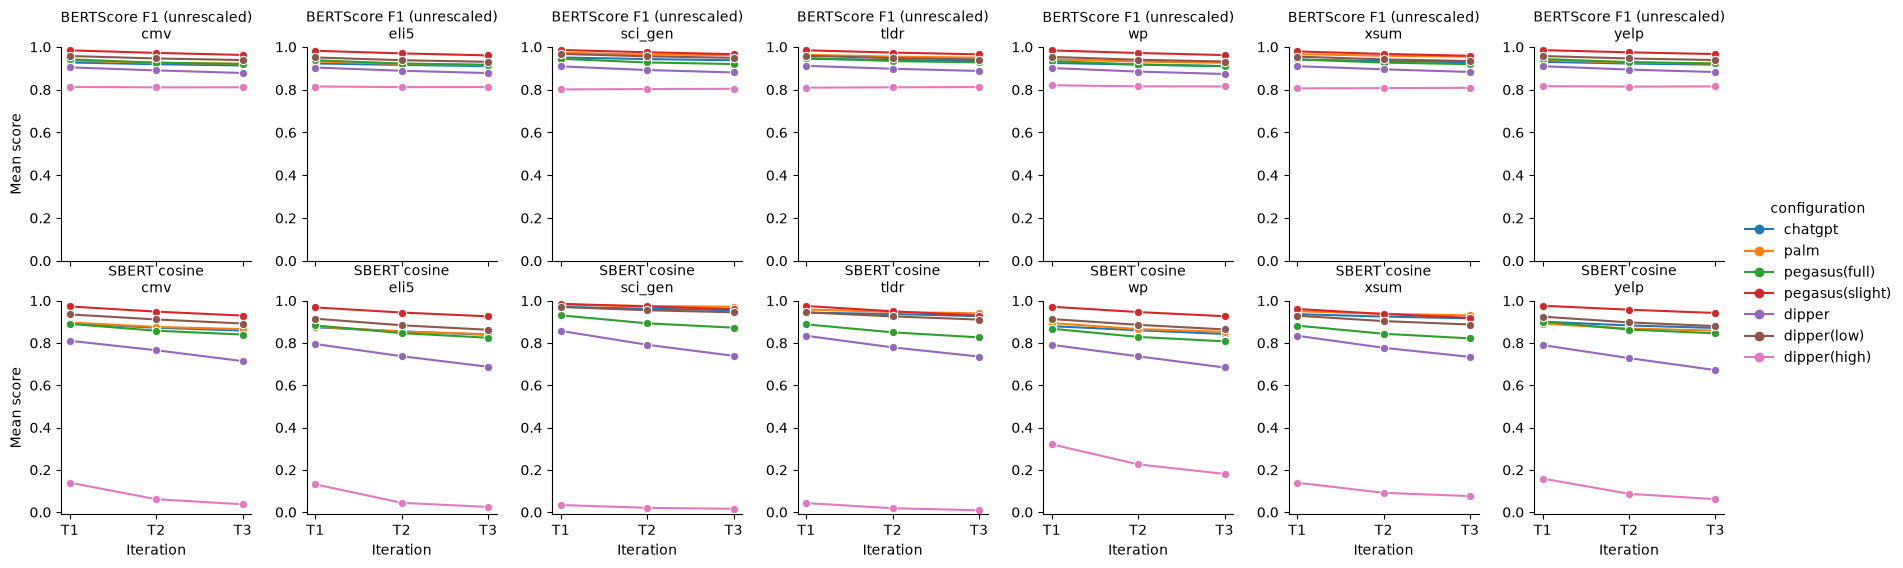

In [56]:
semantic_plot_data = four_metric_by_domain.melt(
    id_vars=["domain", "configuration", "iteration"],
    value_vars=["mean_BERTScore_F1", "mean_SBERT_cosine"],
    var_name="metric",
    value_name="score",
)

semantic_plot_data["metric"] = semantic_plot_data["metric"].map({
    "mean_BERTScore_F1": "BERTScore F1 (unrescaled)",
    "mean_SBERT_cosine": "SBERT cosine",
})

grid = sns.relplot(
    data=semantic_plot_data,
    x="iteration",
    y="score",
    hue="configuration",
    hue_order=list(configuration_map),
    row="metric",
    col="domain",
    col_order=sorted(sbert_datasets),
    kind="line",
    marker="o",
    estimator=None,
    palette="tab10",
    height=2.8,
    aspect=0.9,
    facet_kws={"sharex": True, "sharey": False},
)

grid.set_titles("{row_name}\n{col_name}")
grid.set_axis_labels("Iteration", "Mean score")

for row_index, axes_row in enumerate(grid.axes):
    metric_name = [
        "BERTScore F1 (unrescaled)",
        "SBERT cosine",
    ][row_index]

    values = semantic_plot_data.loc[
        semantic_plot_data["metric"].eq(metric_name),
        "score",
    ]
    lower = max(-1, min(0, values.min() - 0.02))

    for ax in axes_row:
        ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])
        ax.set_ylim(lower, 1.0)

grid.figure.savefig(
    figures_dir / "10_semantic_metrics_matched_by_domain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()